# Mount Drive


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Data check


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
!unzip -qo /content/drive/MyDrive/RAC/archive.zip

In [ ]:
def count_files_in_subfolders(directory):
    total_files = 0
    folder_file_counts = {}

    for root, dirs, files in os.walk(directory):
        if root == directory:
            continue
        folder_name = os.path.basename(root)
        file_count = len(files)
        total_files += file_count
        folder_file_counts[folder_name] = file_count

    print(f"Total files: {total_files}\n")
    accumulated_ratio = 0
    for folder_name, file_count in folder_file_counts.items():
        if file_count > 0:
            ratio = file_count / total_files if total_files > 0 else 0
            print(f"Folder: {folder_name} - File count: {file_count} - Ratio: {ratio:.2%}")
            accumulated_ratio += ratio
    print(f"Sum of ratios (as float): {accumulated_ratio:.2f}")

In [ ]:
def plot_file_count_in_subfolders(root_dir):
    subfolder_counts = []

    # Iterate through each subfolder in the given directory
    for subfolder in os.listdir(root_dir):
        subfolder_path = os.path.join(root_dir, subfolder)
        if os.path.isdir(subfolder_path):
            file_count = len(os.listdir(subfolder_path))
            subfolder_counts.append({'Subfolder': subfolder, 'FileCount': file_count})

    # Create DataFrame from the counts
    df = pd.DataFrame(subfolder_counts)

    # Check if DataFrame is empty
    if df.empty:
        print("DataFrame is empty. No files found in subfolders.")
        return

    print(df)  # Check the DataFrame structure

    # Create the bar plot
    plt.figure(figsize=(10, 6))  # Adjust figure size as needed
    sns.barplot(x='Subfolder', y='FileCount', data=df, palette='Blues_d')

    # Rotate x labels for better readability
    plt.xticks(rotation=45, ha='right')
    plt.title('File Count in Subfolders')
    plt.ylabel('Number of Files')
    plt.xlabel('Subfolder')
    plt.tight_layout()  # Adjust layout
    plt.show()

In [ ]:
count_files_in_subfolders('/content/drive/MyDrive/RAC/Wound_dataset')

Total files: 2940

Folder: Burns - File count: 134 - Ratio: 4.56%
Folder: Bruises - File count: 242 - Ratio: 8.23%
Folder: Cut - File count: 100 - Ratio: 3.40%
Folder: Venous Wounds - File count: 494 - Ratio: 16.80%
Folder: Abrasions - File count: 164 - Ratio: 5.58%
Folder: Surgical Wounds - File count: 420 - Ratio: 14.29%
Folder: Normal - File count: 200 - Ratio: 6.80%
Folder: Pressure Wounds - File count: 602 - Ratio: 20.48%
Folder: Diabetic Wounds - File count: 462 - Ratio: 15.71%
Folder: Laseration - File count: 122 - Ratio: 4.15%
Sum of ratios (as float): 1.00


         Subfolder  FileCount
0            Burns        134
1          Bruises        242
2              Cut        100
3    Venous Wounds        494
4        Abrasions        164
5  Surgical Wounds        420
6           Normal        200
7  Pressure Wounds        602
8  Diabetic Wounds        462
9       Laseration        122


<ipython-input-5-24e8cfa4c09d>:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Subfolder', y='FileCount', data=df, palette='Blues_d')


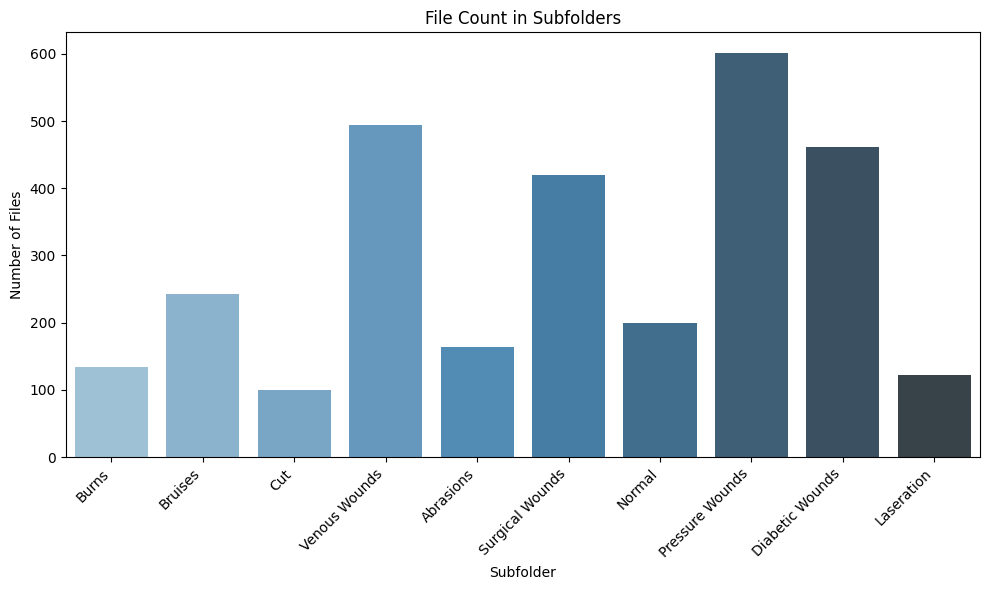

In [ ]:
plot_file_count_in_subfolders('/content/drive/MyDrive/RAC/Wound_dataset')

In [ ]:
!rm -r /content/drive/MyDrive/RAC/Wound_dataset/Normal

# Imbalanced Data with Random

In [ ]:
import os
import random
import shutil

def random_file_picker_and_copier(root_path, output_path, n_files=1, seed=None):
    """
    Randomly pick n files from each class directory in the root_path and copy them to the output_path.

    Args:
        root_path (str): Path to the root directory containing class subdirectories.
        output_path (str): Path to the output directory where files will be copied.
        n_files (int): Number of files to pick from each class.
        seed (int, optional): Seed for random number generator. If None, uses system time.

    Returns:
        dict: A dictionary where keys are class names and values are lists of copied file paths.
    """
    # Set the random seed
    random.seed(seed)

    copied_files = {}

    # Iterate over each class directory in the root path
    for class_name in os.listdir(root_path):
        class_path = os.path.join(root_path, class_name)

        # Skip if it's not a directory
        if not os.path.isdir(class_path):
            continue

        # Get all files in the current class directory
        all_files = [
            os.path.join(class_path, f)
            for f in os.listdir(class_path)
            if os.path.isfile(os.path.join(class_path, f))
        ]

        # Randomly select n files (or fewer if not enough files are available)
        selected_files = random.sample(all_files, min(n_files, len(all_files)))

        # Create output directory for the current class
        class_output_path = os.path.join(output_path, class_name)
        os.makedirs(class_output_path, exist_ok=True)

        # Copy the selected files to the output directory
        copied = []
        for file_path in selected_files:
            file_name = os.path.basename(file_path)
            dest_path = os.path.join(class_output_path, file_name)
            shutil.copy2(file_path, dest_path)
            copied.append(dest_path)

        # Store the copied files for the current class
        copied_files[class_name] = copied

    return copied_files

In [ ]:
# Example usage
root_path = "/content/drive/MyDrive/RAC/Wound_dataset"  # Replace with your dataset path
output_path = "/content/drive/MyDrive/RAC/Data"  # Replace with your desired output path
n_files_to_pick = 100  # Adjust to the number of files you want to pick from each class
seed_value = 54  # Optional seed for reproducibility

copied_files = random_file_picker_and_copier(root_path, output_path, n_files_to_pick, seed=seed_value)

# Print summary
for class_name, files in copied_files.items():
    print(f"Class: {class_name} - Files copied: {len(files)}")


Class: Burns - Files copied: 100
Class: Bruises - Files copied: 100
Class: Cut - Files copied: 100
Class: Venous Wounds - Files copied: 100
Class: Abrasions - Files copied: 100
Class: Surgical Wounds - Files copied: 100
Class: Pressure Wounds - Files copied: 100
Class: Diabetic Wounds - Files copied: 100
Class: Laseration - Files copied: 100


         Subfolder  FileCount
0            Burns        100
1          Bruises        100
2              Cut        100
3    Venous Wounds        100
4        Abrasions        100
5  Surgical Wounds        100
6  Pressure Wounds        100
7  Diabetic Wounds        100
8       Laseration        100


<ipython-input-5-24e8cfa4c09d>:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Subfolder', y='FileCount', data=df, palette='Blues_d')


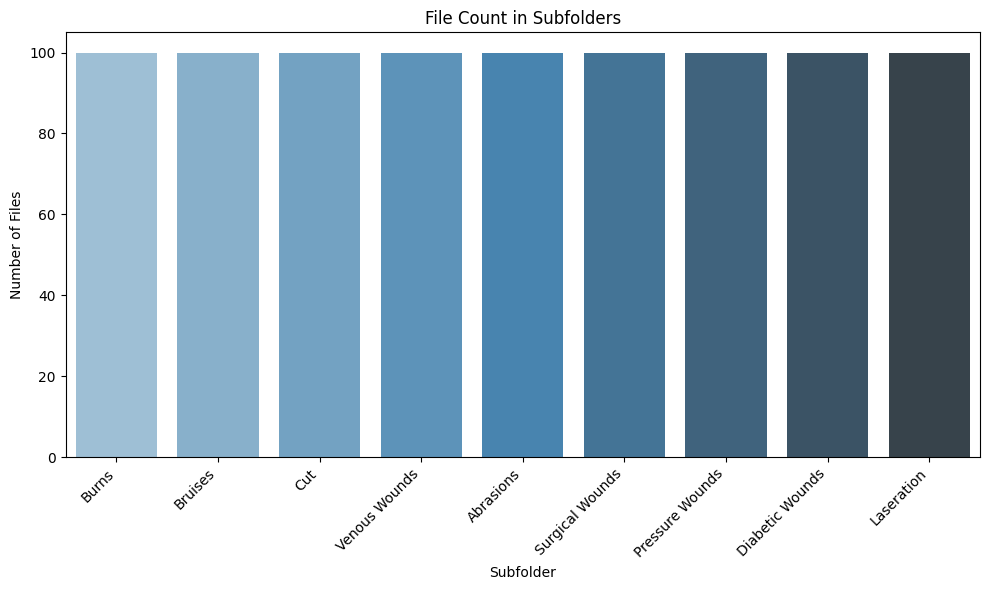

In [ ]:
plot_file_count_in_subfolders('/content/drive/MyDrive/RAC/Data')

# Check image dimensions

In [ ]:
import os
from PIL import Image
from collections import Counter

def check_image_sizes(input_dir: str):
    # เก็บข้อมูลขนาดของภาพในแต่ละคลาส
    class_sizes = {}

    for class_name in os.listdir(input_dir):
        class_dir = os.path.join(input_dir, class_name)
        if os.path.isdir(class_dir):
            class_sizes[class_name] = []

            # ตรวจสอบไฟล์ภาพในโฟลเดอร์
            for image_file in os.listdir(class_dir):
                if image_file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif')):
                    image_path = os.path.join(class_dir, image_file)
                    try:
                        with Image.open(image_path) as img:
                            # เก็บขนาดของภาพ
                            class_sizes[class_name].append(img.size)
                    except Exception as e:
                        print(f"Error loading {image_file}: {e}")

    # สรุปขนาดภาพในแต่ละคลาส
    for class_name, sizes in class_sizes.items():
        print(f"Class: {class_name}")
        size_counts = Counter(sizes)
        for size, count in size_counts.items():
            print(f"  Size: {size[0]}x{size[1]}, Count: {count}")

# ตัวอย่างการใช้งาน
input_dir = '/content/drive/MyDrive/RAC/Data'
check_image_sizes(input_dir)


Class: Burns
  Size: 640x640, Count: 70
  Size: 154x106, Count: 4
  Size: 154x105, Count: 13
  Size: 154x109, Count: 11
  Size: 154x99, Count: 2
Class: Bruises
  Size: 640x640, Count: 100
Class: Cut
  Size: 640x640, Count: 100
Class: Venous Wounds
  Size: 270x324, Count: 1
  Size: 129x130, Count: 2
  Size: 179x178, Count: 1
  Size: 479x479, Count: 1
  Size: 135x136, Count: 1
  Size: 164x138, Count: 1
  Size: 171x171, Count: 1
  Size: 188x213, Count: 1
  Size: 231x231, Count: 1
  Size: 293x302, Count: 1
  Size: 111x111, Count: 2
  Size: 320x383, Count: 2
  Size: 201x201, Count: 1
  Size: 240x240, Count: 3
  Size: 143x143, Count: 1
  Size: 222x222, Count: 1
  Size: 290x240, Count: 2
  Size: 75x89, Count: 1
  Size: 124x124, Count: 1
  Size: 196x196, Count: 1
  Size: 246x246, Count: 1
  Size: 185x185, Count: 2
  Size: 230x240, Count: 1
  Size: 320x366, Count: 2
  Size: 138x138, Count: 1
  Size: 486x485, Count: 2
  Size: 176x176, Count: 1
  Size: 207x207, Count: 4
  Size: 309x308, Count: 1


# Augment picture

In [ ]:
import os
import cv2
import numpy as np
import albumentations as A
from tqdm import tqdm

class WoundImagePreprocessor:
    def __init__(self, input_dir, output_dir, resize_dim=(224, 224),
                 class_names=['Abrasions', 'Bruises', 'Burns', 'Cut', 'Diabetic Wounds',
                              'Laseration', 'Pressure Wounds', 'Surgical Wounds', 'Venous Wounds']):
        self.input_dir = input_dir
        self.output_dir = output_dir
        self.resize_dim = resize_dim
        self.class_names = class_names

        # Create output directory
        os.makedirs(output_dir, exist_ok=True)

    def _resize_image(self, image):
        """Resize image to target dimensions"""
        return cv2.resize(image, self.resize_dim, interpolation=cv2.INTER_LANCZOS4)

    def _create_augmentations(self):
        """Create augmentation transformations"""
        return {
            'brightness_contrast': A.Compose([
                A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'medical_noise': A.Compose([
                A.GaussNoise(var_limit=(10.0, 30.0), p=0.3),
                A.MedianBlur(blur_limit=3, p=0.2),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'color_jitter': A.Compose([
                A.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.1, p=0.5),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'geometric_transforms': A.Compose([
                A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.15, rotate_limit=20, p=0.5),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'rotate': A.Compose([
                A.Rotate(limit=40, p=1.0),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'affine_shear': A.Compose([
                A.Affine(shear=15, p=1.0),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'random_scale': A.Compose([
                A.RandomScale(scale_limit=0.3, p=1.0),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'horizontal_flip': A.Compose([
                A.HorizontalFlip(p=1.0),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'vertical_flip': A.Compose([
                A.VerticalFlip(p=1.0),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ])
        }

    def preprocess_and_augment(self):
        """Process and augment images for each class"""
        augmentations = self._create_augmentations()

        for class_name in self.class_names:
            # Input directory for the current class
            class_input_dir = os.path.join(self.input_dir, class_name)
            class_output_dir = os.path.join(self.output_dir, class_name)

            # Create output directory for this class
            os.makedirs(class_output_dir, exist_ok=True)

            # Process each image in the class
            for image_file in tqdm(os.listdir(class_input_dir), desc=f"Processing {class_name}"):
                if image_file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif')):
                    # Read and convert image
                    image_path = os.path.join(class_input_dir, image_file)
                    image = cv2.imread(image_path)
                    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

                    # Resize image
                    resized_image = self._resize_image(image)

                    # Save resized image
                    resized_output_path = os.path.join(class_output_dir, f"resized_{image_file}")
                    cv2.imwrite(resized_output_path, cv2.cvtColor(resized_image, cv2.COLOR_RGB2BGR))

                    # Perform augmentations
                    for aug_name, aug_transform in augmentations.items():
                        augmented_image = aug_transform(image=resized_image)['image']
                        aug_output_filename = f"aug_{aug_name}_{image_file}"
                        aug_output_path = os.path.join(class_output_dir, aug_output_filename)
                        cv2.imwrite(aug_output_path, cv2.cvtColor(augmented_image, cv2.COLOR_RGB2BGR))

def main():
    # Directories for input and output
    input_dir = '/content/drive/MyDrive/RAC/Data'
    output_dir = '/content/drive/MyDrive/RAC/Data224'

    # Initialize and run preprocessing
    preprocessor = WoundImagePreprocessor(input_dir=input_dir, output_dir=output_dir)
    preprocessor.preprocess_and_augment()

if __name__ == "__main__":
    main()

Processing Venous Wounds: 100%|██████████| 100/100 [00:09<00:00, 10.77it/s]


         Subfolder  FileCount
0        Abrasions       1000
1          Bruises       1000
2            Burns       1000
3              Cut       1000
4  Diabetic Wounds       1000
5       Laseration       1000
6  Pressure Wounds       1000
7  Surgical Wounds       1000
8    Venous Wounds       1000


<ipython-input-5-24e8cfa4c09d>:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Subfolder', y='FileCount', data=df, palette='Blues_d')


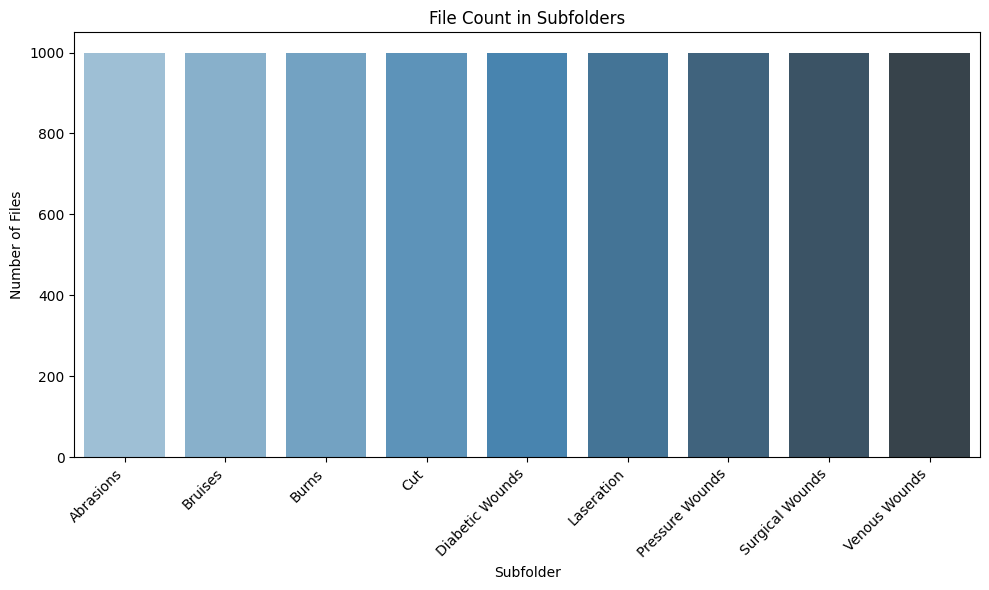

In [ ]:
plot_file_count_in_subfolders('/content/drive/MyDrive/RAC/Data224')

# Splitfolders

In [ ]:
!pip install -q split-folders

In [ ]:
import splitfolders
splitfolders.ratio("/content/drive/MyDrive/RAC/Data224",
                    output="/content/drive/MyDrive/RAC/Datat",
                    seed=69,
                    ratio=(.8, 0.1, .1),
                    move=False)

Copying files: 9000 files [02:45, 54.30 files/s]


         Subfolder  FileCount
0        Abrasions        100
1          Bruises        100
2            Burns        100
3              Cut        100
4  Diabetic Wounds        100
5       Laseration        100
6  Pressure Wounds        100
7  Surgical Wounds        100
8    Venous Wounds        100


<ipython-input-5-24e8cfa4c09d>:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Subfolder', y='FileCount', data=df, palette='Blues_d')


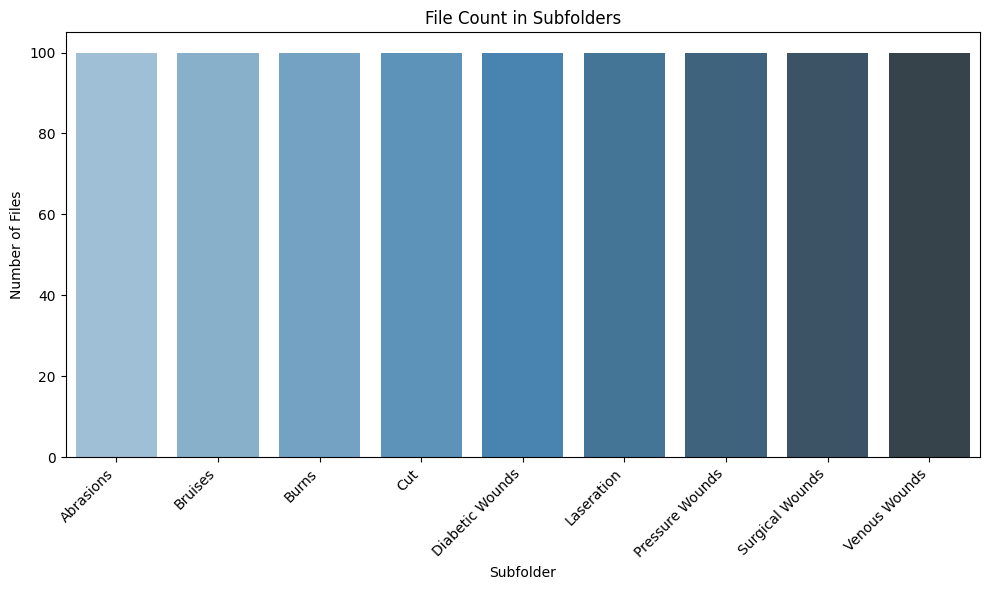

In [ ]:
plot_file_count_in_subfolders('/content/drive/MyDrive/RAC/Datat/test')

         Subfolder  FileCount
0        Abrasions        800
1          Bruises        800
2            Burns        800
3              Cut        800
4  Diabetic Wounds        800
5       Laseration        800
6  Pressure Wounds        800
7  Surgical Wounds        800
8    Venous Wounds        800


<ipython-input-5-24e8cfa4c09d>:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Subfolder', y='FileCount', data=df, palette='Blues_d')


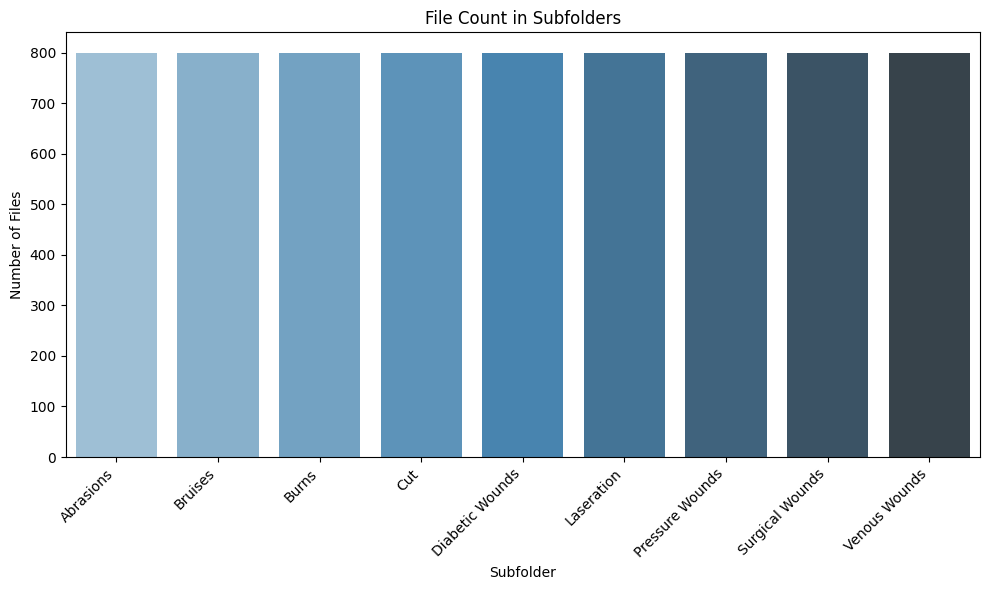

In [ ]:
plot_file_count_in_subfolders('/content/drive/MyDrive/RAC/Datat/train')

         Subfolder  FileCount
0        Abrasions        100
1          Bruises        100
2            Burns        100
3              Cut        100
4  Diabetic Wounds        100
5       Laseration        100
6  Pressure Wounds        100
7  Surgical Wounds        100
8    Venous Wounds        100


<ipython-input-5-24e8cfa4c09d>:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Subfolder', y='FileCount', data=df, palette='Blues_d')


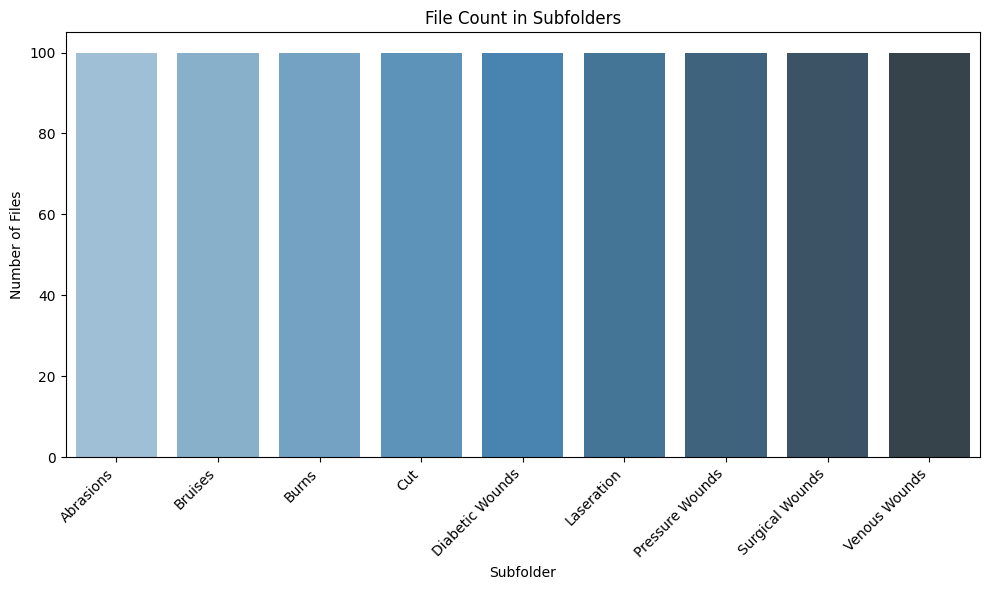

In [ ]:
plot_file_count_in_subfolders('/content/drive/MyDrive/RAC/Datat/val')

# Check image dimensions

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
from collections import Counter

def get_image_dimensions(root_dir):
    image_dimensions = []
    for subdir, dirs, files in os.walk(root_dir):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.gif')):
                file_path = os.path.join(subdir, file)
                image = cv2.imread(file_path)
                if image is not None:
                    dimensions = image.shape
                    image_dimensions.append(dimensions)
                else:
                    print(f"Error: Unable to read image at {file_path}")
    return image_dimensions

def plot_dimensions(dimensions):
    # Count the occurrences of each dimension
    dimension_counts = Counter(dimensions)
    # Separate the dimensions and their counts
    dims, counts = zip(*dimension_counts.items())
    # Create a bar chart
    plt.bar(range(len(dims)), counts, tick_label=[f"{d[0]}x{d[1]}" for d in dims])
    plt.xlabel('Image Dimensions')
    plt.ylabel('Frequency')
    plt.title('Distribution of Image Dimensions')
    plt.xticks(rotation=90)
    plt.show()

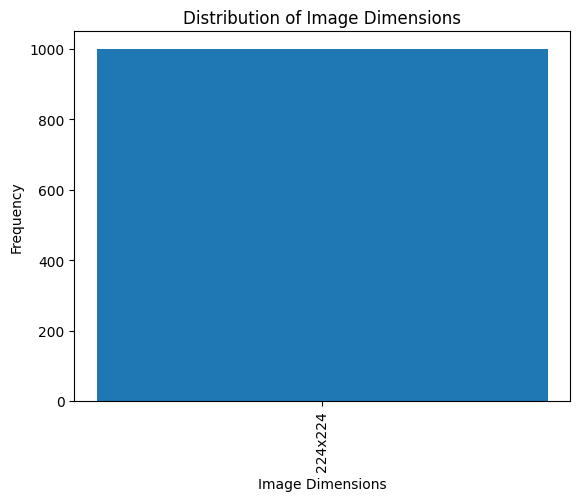

In [ ]:
shape_dict = get_image_dimensions('/content/drive/MyDrive/RAC/Data224/Abrasions')
plot_dimensions(shape_dict)

# Train Nomal Model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.137889,0.428191,0.865556,0.134444,01:01


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.482310,0.111949,0.964444,0.035556,00:59
1,0.217348,0.050517,0.986667,0.013333,01:00
2,0.128515,0.030431,0.992222,0.007778,01:02
3,0.123966,0.044368,0.986667,0.013333,00:59
4,0.100023,0.043700,0.990000,0.010000,01:02
5,0.081984,0.042326,0.982222,0.017778,00:57
6,0.097208,0.031226,0.990000,0.010000,00:58
7,0.074947,0.017861,0.995556,0.004444,00:59
8,0.057083,0.026048,0.990000,0.010000,00:59
9,0.044959,0.011138,0.995556,0.004444,01:02


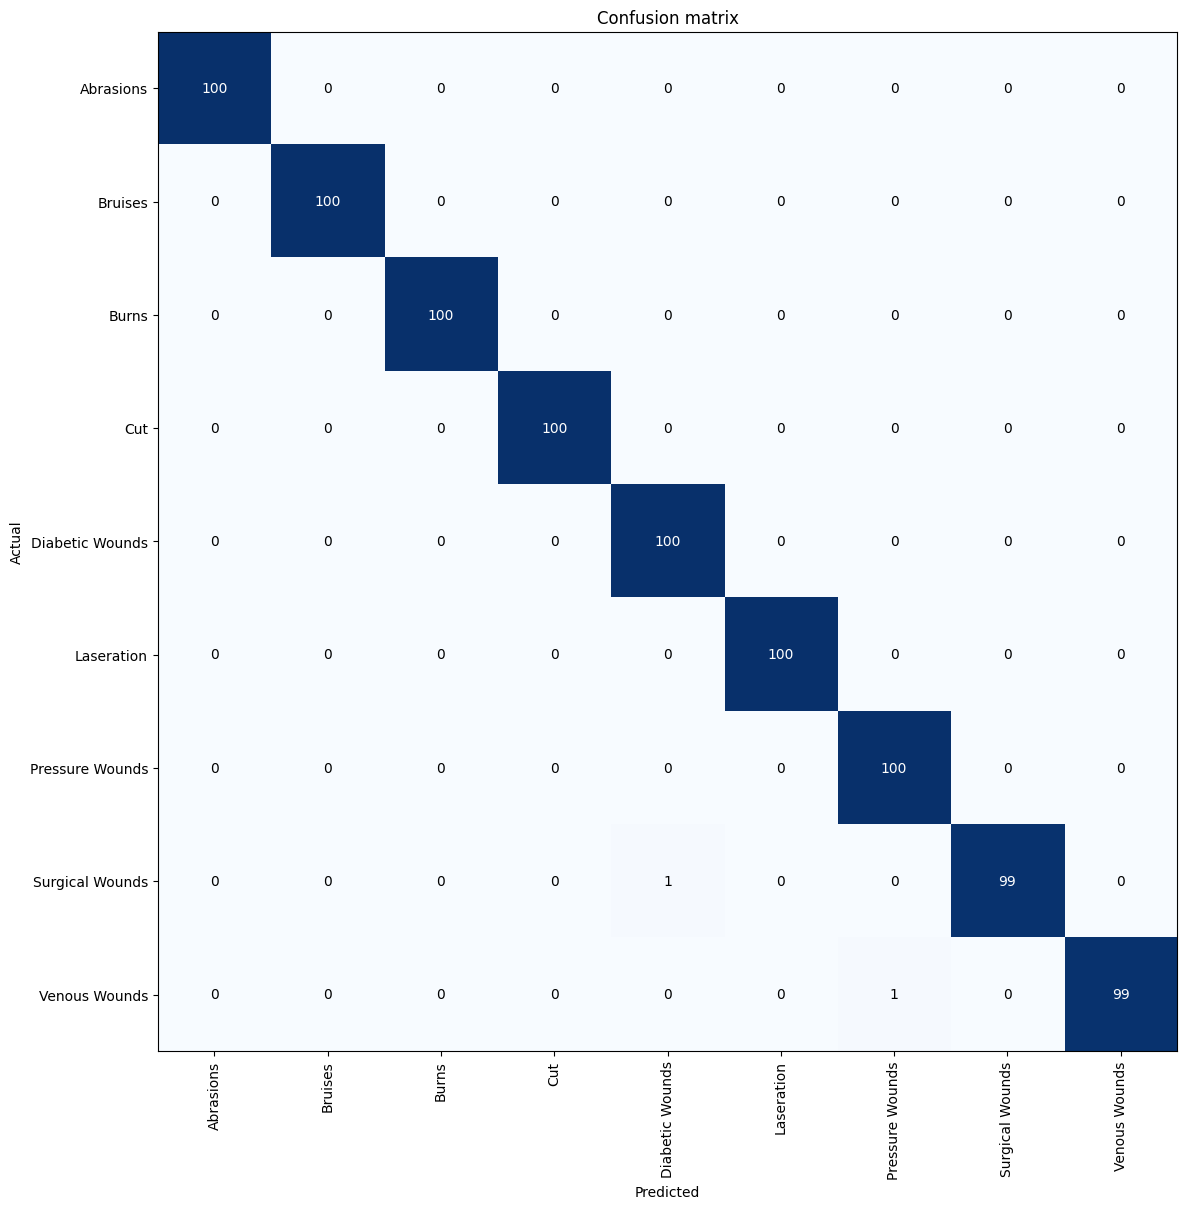

In [ ]:
from fastai.vision.all import *
from fastai.optimizer import Adam  # นำเข้า Adam optimizer
from pathlib import Path

# ระบุ Path สำหรับ Dataset
dataset_path = Path('/content/drive/MyDrive/RAC/Datat')  # เปลี่ยนเป็น path จริงของคุณ
train_path = dataset_path / 'train'
valid_path = dataset_path / 'val'

assert train_path.exists(), f"Train path {train_path} does not exist."
assert valid_path.exists(), f"Validation path {valid_path} does not exist."

# สร้าง DataLoader
dataloaders = ImageDataLoaders.from_folder(
    dataset_path,
    train='train',
    valid='val',
    item_tfms=Resize(224),
    batch_tfms=aug_transforms(
        max_rotate=20, max_zoom=1.1, max_lighting=0.2, max_warp=0.2
    ),
    bs=32
)

# กำหนด loss function ที่ต้องการ
best_loss_func = CrossEntropyLossFlat()

# สร้างโมเดลด้วย ResNet34 และใช้ Adam optimizer
learn = vision_learner(
    dataloaders,
    resnet34,
    metrics=[accuracy, error_rate],
    loss_func=best_loss_func,
    opt_func=Adam  # ใช้ Adam optimizer
)

# กำหนด learning rate และ weight decay
best_lr = 0.0015071939747309817
best_wd = 2.7069127767424798e-05

# ใช้ Fine-tune ให้ FastAI ปรับการ freeze/unfreeze layers โดยอัตโนมัติ
learn.fine_tune(epochs=20, base_lr=best_lr, wd=best_wd)

# วิเคราะห์ผลลัพธ์จากโมเดล
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix(figsize=(12, 12), dpi=100)

# บันทึกโมเดล
learn.export('/content/drive/MyDrive/RAC/model93.pkl')


# Evaluate Model

์Evaluate Nomal modle and pruning modle

In [ ]:
from fastai.vision.all import *
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, recall_score
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def evaluate_fastai_model(model_path, test_data_path):
    """
    โหลดโมเดลที่ถูกเทรนโดย FastAI และทดสอบกับชุดข้อมูลที่กำหนด

    Parameters:
    - model_path (str): Path ของไฟล์โมเดล (.pkl) ที่ต้องการโหลด
    - test_data_path (str): Path ของโฟลเดอร์ที่มีชุดข้อมูลทดสอบ (ต้องอยู่ในโครงสร้าง ImageFolder)
    """

    # โหลดโมเดล FastAI
    learn = load_learner(model_path)

    # โหลดข้อมูลทดสอบ
    test_files = get_image_files(test_data_path)

    # กำหนด labels เป็น 0 ชั่วคราว (เพื่อให้ FastAI ทำงาน)
    test_dl = learn.dls.test_dl(test_files, with_labels=True)

    # ทำการทำนาย
    preds, _ = learn.get_preds(dl=test_dl)
    preds_class = torch.argmax(preds, dim=1).numpy()

    # สร้าง labels ตามลำดับไฟล์ (ชื่อโฟลเดอร์ของไฟล์เป็น label จริง)
    targets_class = np.array([learn.dls.vocab.o2i[f.parent.name] for f in test_files])

    # คำนวณค่าต่างๆ
    acc = accuracy_score(targets_class, preds_class)
    f1 = f1_score(targets_class, preds_class, average='weighted')
    recall = recall_score(targets_class, preds_class, average='weighted')
    conf_matrix = confusion_matrix(targets_class, preds_class)

    # แสดงผลลัพธ์
    print(f"Accuracy: {acc:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"Recall: {recall:.4f}")
    print("Classes from trained model:", learn.dls.vocab)
    print(f"Number of test images: {len(test_files)}")
    print("Confusion Matrix:")
    print(conf_matrix)

    # พล็อต Confusion Matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=learn.dls.vocab, yticklabels=learn.dls.vocab)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()



Evaluate Knowledge Distillation modle

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, recall_score
import seaborn as sns
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import numpy as np
from torchvision import models
import torch.nn as nn

# ประกาศคลาส StudentResNet (โมเดลที่ถูกฝึกจากการทำ Knowledge Distillation)
class StudentResNet(nn.Module):
    def __init__(self):
        super(StudentResNet, self).__init__()
        self.student = models.resnet18(pretrained=False)  # โมเดล ResNet18
        num_ftrs = self.student.fc.in_features
        self.student.fc = nn.Linear(num_ftrs, 9)  # กำหนด output สำหรับ 9 classes

    def forward(self, x):
        return self.student(x)

def evaluate_kd_model(model_path, test_data_path):
    """
    โหลดโมเดลที่ผ่านการทำ Knowledge Distillation และทดสอบกับชุดข้อมูลที่กำหนด
    """

    # ตรวจสอบว่าเรามี GPU หรือไม่ ถ้ามีจะใช้ GPU ถ้าไม่มีจะใช้ CPU
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    # สร้าง DataLoader สำหรับ test dataset
    data_transforms = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    test_dataset = datasets.ImageFolder(test_data_path, transform=data_transforms)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

    # โหลดโมเดล KD (โมเดล Student)
    student_model = StudentResNet()  # โมเดลที่ถูกฝึกโดยการทำ Knowledge Distillation
    student_model.load_state_dict(torch.load(model_path))
    student_model = student_model.to(device)
    student_model.eval()  # ตั้งโมเดลเป็นโหมด evaluation

    # ทำการทำนาย
    preds_class = []
    targets_class = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = student_model(inputs)
            _, predicted = torch.max(outputs, 1)

            preds_class.extend(predicted.cpu().numpy())
            targets_class.extend(labels.cpu().numpy())

    # คำนวณค่าต่างๆ
    acc = accuracy_score(targets_class, preds_class)
    f1 = f1_score(targets_class, preds_class, average='weighted')
    recall = recall_score(targets_class, preds_class, average='weighted')
    conf_matrix = confusion_matrix(targets_class, preds_class)

    # แสดงผลลัพธ์
    print(f"Accuracy: {acc:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"Recall: {recall:.4f}")
    print("Classes from trained model:", test_dataset.classes)
    print(f"Number of test images: {len(test_dataset)}")
    print("Confusion Matrix:")
    print(conf_matrix)

    # พล็อต Confusion Matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=test_dataset.classes, yticklabels=test_dataset.classes)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()

Evaluate Layer Truncation modle

In [ ]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, recall_score
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# ตรวจสอบว่าใช้ GPU หรือไม่
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# **1. กำหนดโครงสร้างของ Truncated Model**
class TruncatedResNet34(nn.Module):
    def __init__(self, num_classes):
        super(TruncatedResNet34, self).__init__()
        base_model = models.resnet34(pretrained=False)  # โหลดโครงสร้าง ResNet34
        self.features = nn.Sequential(*list(base_model.children())[:-1])  # ตัด Fully Connected Layer
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, num_classes)  # Fully Connected Layer ใหม่
        )

    def forward(self, x):
        x = self.features(x)
        x = self.fc(x)
        return x

# **2. ฟังก์ชัน Evaluate Model**
def evaluate_truncated_model(model_path, test_data_path):
    """
    โหลดโมเดลที่ผ่านการทำ Layer Truncation และทดสอบกับชุดข้อมูลที่กำหนด
    """

    # โหลดโมเดล
    num_classes = 9  # จำนวนคลาส
    model = TruncatedResNet34(num_classes).to(device)

    # ✅ ใช้ strict=False เพื่อข้ามพารามิเตอร์ที่ไม่ตรงกัน
    model.load_state_dict(torch.load(model_path), strict=False)
    model.eval()

    # สร้าง DataLoader สำหรับชุดทดสอบ
    data_transforms = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    test_dataset = datasets.ImageFolder(test_data_path, transform=data_transforms)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

    # ทำการทำนาย
    preds_class = []
    targets_class = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)

            preds_class.extend(predicted.cpu().numpy())
            targets_class.extend(labels.cpu().numpy())

    # คำนวณค่าต่างๆ
    acc = accuracy_score(targets_class, preds_class)
    f1 = f1_score(targets_class, preds_class, average='weighted')
    recall = recall_score(targets_class, preds_class, average='weighted')
    conf_matrix = confusion_matrix(targets_class, preds_class)

    # แสดงผลลัพธ์
    print(f"Accuracy: {acc:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"Recall: {recall:.4f}")
    print("Classes from trained model:", test_dataset.classes)
    print(f"Number of test images: {len(test_dataset)}")
    print("Confusion Matrix:")
    print(conf_matrix)

    # พล็อต Confusion Matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=test_dataset.classes, yticklabels=test_dataset.classes)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()

Using device: cuda


# Evaluate Nomal Model

Accuracy: 0.9956
F1 Score: 0.9956
Recall: 0.9956
Classes from trained model: ['Abrasions', 'Bruises', 'Burns', 'Cut', 'Diabetic Wounds', 'Laseration', 'Pressure Wounds', 'Surgical Wounds', 'Venous Wounds']
Number of test images: 900
Confusion Matrix:
[[ 99   0   0   0   0   0   0   1   0]
 [  0 100   0   0   0   0   0   0   0]
 [  0   0 100   0   0   0   0   0   0]
 [  0   0   0 100   0   0   0   0   0]
 [  0   0   0   0  99   0   1   0   0]
 [  0   0   0   0   0 100   0   0   0]
 [  0   0   0   0   2   0  98   0   0]
 [  0   0   0   0   0   0   0 100   0]
 [  0   0   0   0   0   0   0   0 100]]


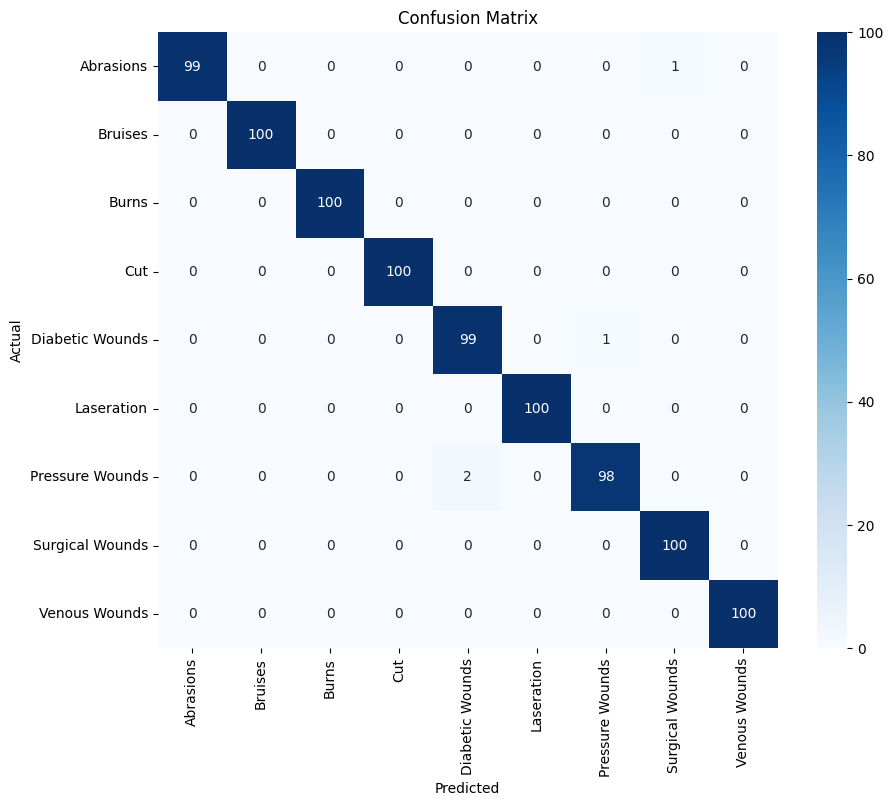

In [ ]:
# -------------- ใช้งานฟังก์ชัน ---------------- #

# กำหนด path ของโมเดลและโฟลเดอร์ที่มีข้อมูลทดสอบ
model_path = "/content/drive/MyDrive/RAC/model93.pkl"  # เปลี่ยนเป็น path ของโมเดลที่ต้องการ
test_data_path = "/content/drive/MyDrive/RAC/Datat/test"  # เปลี่ยนเป็น path ของโฟลเดอร์ภาพ test

# เรียกใช้ฟังก์ชันเพื่อทดสอบโมเดล
evaluate_fastai_model(model_path, test_data_path)


# Pruning

In [ ]:
from fastai.vision.all import *
import torch
import torch.nn.utils.prune as prune

# Load โมเดลที่เทรนเสร็จแล้ว (สมมติว่าไฟล์โมเดลชื่อ 'trained_model.pkl')
learn = load_learner('/content/drive/MyDrive/RAC/model93.pkl')

# ดึงโมเดล PyTorch จาก FastAI Learner
model = learn.model

# 1. ค้นหาเลเยอร์ทั้งหมดที่มี weight สำหรับ Prune
parameters_to_prune = [
    (module, 'weight') for module in model.modules() if hasattr(module, 'weight')
]

# 2. ใช้ Global Pruning แบบ L1Unstructured
print(f"Pruning {len(parameters_to_prune)} layers...")
prune.global_unstructured(
    parameters_to_prune,
    pruning_method=prune.L1Unstructured,
    amount=0.5  # Prune 50% ของ weights ในทุกเลเยอร์
)

# 3. ตรวจสอบพารามิเตอร์หลัง Pruning
pruned_parameters = 0
total_parameters = 0
for name, module in model.named_modules():
    if hasattr(module, 'weight'):
        total_parameters += module.weight.numel()
        pruned_parameters += (module.weight == 0).sum().item()
        print(f"Layer: {name}, Total Params: {module.weight.numel()}, Pruned Params: {(module.weight == 0).sum().item()}")

print(f"Total Pruned Parameters: {pruned_parameters}/{total_parameters} ({pruned_parameters / total_parameters * 100:.2f}%)")

# 4. ลบ mask และปรับโมเดลให้พร้อมใช้งาน
for module, param in parameters_to_prune:
    prune.remove(module, 'weight')  # ลบ mask เพื่อให้ใช้งานโมเดลได้ใน production

# 5. บันทึกโมเดลหลัง Pruning
learn.export('/content/drive/MyDrive/RAC/pruned_model.pkl')  # Export โมเดลหลัง Pruning
print("Pruned model exported to '/path/to/pruned_model.pkl'")


Pruning 76 layers...
Layer: 0.0, Total Params: 9408, Pruned Params: 2555
Layer: 0.1, Total Params: 64, Pruned Params: 10
Layer: 0.4.0.conv1, Total Params: 36864, Pruned Params: 14528
Layer: 0.4.0.bn1, Total Params: 64, Pruned Params: 0
Layer: 0.4.0.conv2, Total Params: 36864, Pruned Params: 11167
Layer: 0.4.0.bn2, Total Params: 64, Pruned Params: 0
Layer: 0.4.1.conv1, Total Params: 36864, Pruned Params: 10364
Layer: 0.4.1.bn1, Total Params: 64, Pruned Params: 0
Layer: 0.4.1.conv2, Total Params: 36864, Pruned Params: 10618
Layer: 0.4.1.bn2, Total Params: 64, Pruned Params: 0
Layer: 0.4.2.conv1, Total Params: 36864, Pruned Params: 10035
Layer: 0.4.2.bn1, Total Params: 64, Pruned Params: 0
Layer: 0.4.2.conv2, Total Params: 36864, Pruned Params: 11227
Layer: 0.4.2.bn2, Total Params: 64, Pruned Params: 2
Layer: 0.5.0.conv1, Total Params: 73728, Pruned Params: 22259
Layer: 0.5.0.bn1, Total Params: 128, Pruned Params: 0
Layer: 0.5.0.conv2, Total Params: 147456, Pruned Params: 57355
Layer: 0.5

Accuracy: 0.9933
F1 Score: 0.9933
Recall: 0.9933
Classes from trained model: ['Abrasions', 'Bruises', 'Burns', 'Cut', 'Diabetic Wounds', 'Laseration', 'Pressure Wounds', 'Surgical Wounds', 'Venous Wounds']
Number of test images: 900
Confusion Matrix:
[[100   0   0   0   0   0   0   0   0]
 [  0 100   0   0   0   0   0   0   0]
 [  0   0 100   0   0   0   0   0   0]
 [  0   0   0 100   0   0   0   0   0]
 [  0   0   0   0  99   0   1   0   0]
 [  1   0   0   0   0  99   0   0   0]
 [  0   0   0   0   2   0  98   0   0]
 [  0   0   0   1   0   0   0  98   1]
 [  0   0   0   0   0   0   0   0 100]]


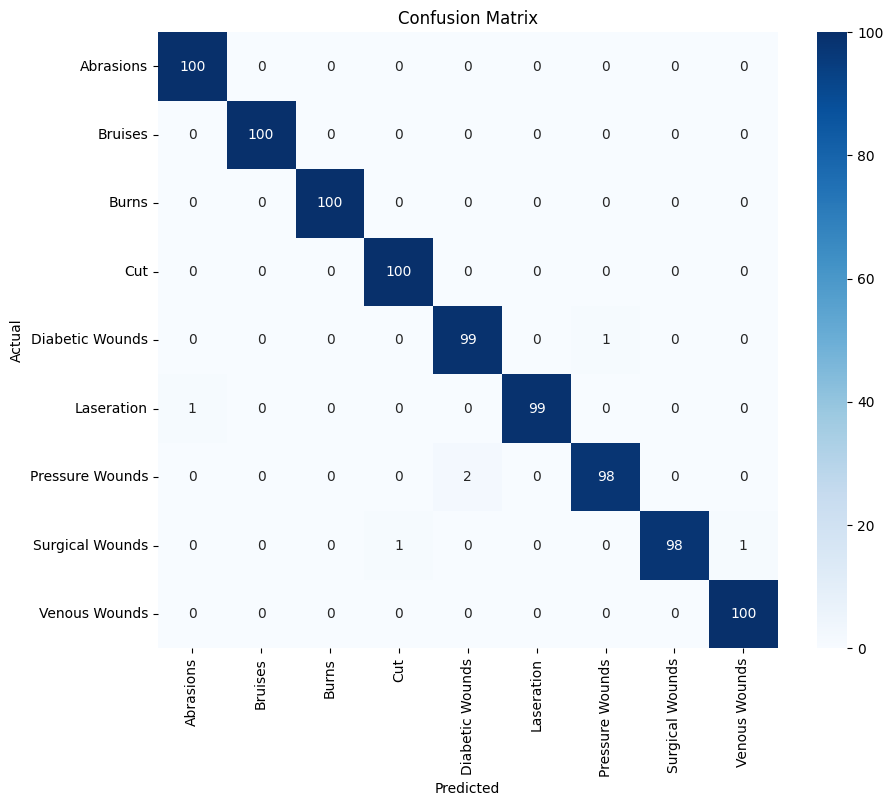

In [ ]:
# -------------- ใช้งานฟังก์ชัน ---------------- #

# กำหนด path ของโมเดลและโฟลเดอร์ที่มีข้อมูลทดสอบ
model_path = "/content/drive/MyDrive/RAC/pruned_model.pkl"  # เปลี่ยนเป็น path ของโมเดลที่ต้องการ
test_data_path = "/content/drive/MyDrive/RAC/Datat/test"  # เปลี่ยนเป็น path ของโฟลเดอร์ภาพ test

# เรียกใช้ฟังก์ชันเพื่อทดสอบโมเดล
evaluate_fastai_model(model_path, test_data_path)


# Knowledge Distillation

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from fastai.vision.all import *

# Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Load Teacher Model from a given .pkl file
teacher_model_path = '/content/drive/MyDrive/RAC/model93.pkl'  # Specify the path to the Teacher Model
teacher_learner = load_learner(teacher_model_path)
teacher_model = teacher_learner.model.to(device)
teacher_model.eval()  # Set model to evaluation mode

# Define Student Model (Reduced ResNet18)
class StudentResNet(nn.Module):
    def __init__(self):
        super(StudentResNet, self).__init__()
        self.student = models.resnet18(pretrained=False)  # Smaller model
        num_ftrs = self.student.fc.in_features
        self.student.fc = nn.Linear(num_ftrs, 9)  # Output for 9 classes

    def forward(self, x):
        return self.student(x)

student_model = StudentResNet().to(device)

# Define KD Loss Function
class KDLoss(nn.Module):
    def __init__(self, alpha=0.5, temperature=4):
        super(KDLoss, self).__init__()
        self.alpha = alpha
        self.temperature = temperature
        self.criterion_ce = nn.CrossEntropyLoss()
        self.criterion_kl = nn.KLDivLoss(reduction='batchmean')

    def forward(self, student_logits, teacher_logits, labels):
        kl_loss = self.criterion_kl(
            F.log_softmax(student_logits / self.temperature, dim=1),
            F.softmax(teacher_logits / self.temperature, dim=1)
        )
        ce_loss = self.criterion_ce(student_logits, labels)
        return (self.alpha * kl_loss * self.temperature * self.temperature) + ((1 - self.alpha) * ce_loss)

# Dataset and DataLoader
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder('/content/drive/MyDrive/RAC/Datat/train', transform=data_transforms)
val_dataset = datasets.ImageFolder('/content/drive/MyDrive/RAC/Datat/val', transform=data_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

# Training Configuration
epochs = 10
lr = 1e-3
optimizer = optim.Adam(student_model.parameters(), lr=lr)
kd_loss_fn = KDLoss(alpha=0.5, temperature=4)

# Training Loop
def train_kd(teacher_model, student_model, train_loader, val_loader, kd_loss_fn, optimizer, epochs):
    teacher_model.eval()
    student_model.train()

    for epoch in range(epochs):
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            with torch.no_grad():
                teacher_logits = teacher_model(inputs)

            student_logits = student_model(inputs)
            loss = kd_loss_fn(student_logits, teacher_logits, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss/len(train_loader):.4f}")

    print("Training Complete")
    return student_model

# Train the Student Model
trained_student_model = train_kd(teacher_model, student_model, train_loader, val_loader, kd_loss_fn, optimizer, epochs)

# Save the Model in .pkl format
student_model_path = '/content/drive/MyDrive/RAC/student_model.pkl'
torch.save(trained_student_model.state_dict(), student_model_path)
print(f"Student Model Saved at {student_model_path}")

Using device: cuda


AttributeError: '_FakeLoader' object has no attribute 'in_order'

Using device: cuda


<ipython-input-23-aaf6142ef83c>:43: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  student_model.load_state_dict(torch.load(model_path))


Accuracy: 0.9089
F1 Score: 0.9092
Recall: 0.9089
Classes from trained model: ['Abrasions', 'Bruises', 'Burns', 'Cut', 'Diabetic Wounds', 'Laseration', 'Pressure Wounds', 'Surgical Wounds', 'Venous Wounds']
Number of test images: 900
Confusion Matrix:
[[94  2  0  0  0  1  0  2  1]
 [ 1 91  3  0  2  0  1  1  1]
 [ 2  0 94  1  0  0  3  0  0]
 [ 2  0  1 97  0  0  0  0  0]
 [ 0  0  0  1 94  0  3  1  1]
 [ 3  0  2  3  3 84  1  4  0]
 [ 1  0  1  0  5  0 88  1  4]
 [ 0  0  5  0  7  1  0 87  0]
 [ 0  0  2  0  5  0  2  2 89]]


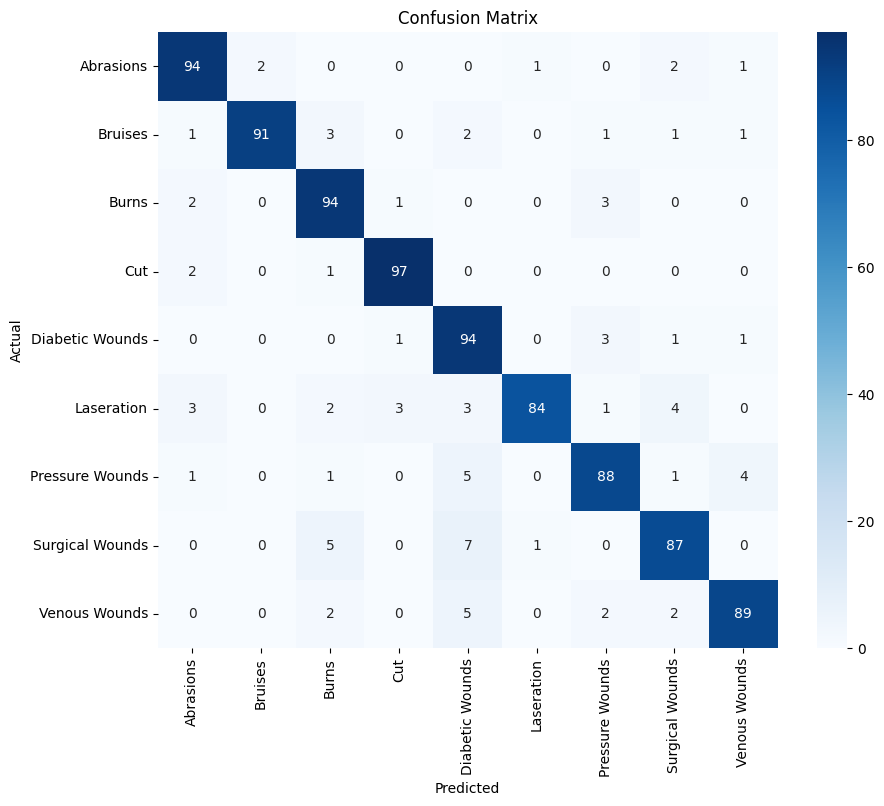

In [ ]:
# -------------- ใช้งานฟังก์ชัน ---------------- #
model_path = '/content/drive/MyDrive/RAC/student_model.pkl'  # โมเดลที่ผ่านการทำ KD
test_data_path = '/content/drive/MyDrive/RAC/Datat/test'  # path สำหรับข้อมูลทดสอบ

evaluate_kd_model(model_path, test_data_path)

# Layer Truncation



In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from fastai.learner import load_learner
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# **1. กำหนดอุปกรณ์**
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# **2. โหลด FastAI Learner**
model_path = "/content/drive/MyDrive/RAC/model93.pkl"  # เปลี่ยนเป็น path ของโมเดล
pretrained_model = load_learner(model_path)          # โหลดโมเดล FastAI Learner
pytorch_model = pretrained_model.model               # ดึงโมเดล PyTorch ออกมา
print(pytorch_model)

# **3. สร้าง Truncated Model**
class TruncatedResNet34(nn.Module):
    def __init__(self, original_model, num_classes):
        super(TruncatedResNet34, self).__init__()
        self.features = nn.Sequential(*list(original_model.children())[:-1]).to(device)  # ตัด Fully Connected Layer และย้ายไปยัง GPU

        # ใช้ข้อมูลจำลองเพื่อตรวจสอบขนาด
        dummy_input = torch.randn(1, 3, 224, 224).to(device)
        with torch.no_grad():
            feature_output = self.features(dummy_input)
            out_features = feature_output.shape[1]  # ขนาดของ channel

        # Fully Connected Layer ใหม่
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(out_features, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.fc(x)
        return x


num_classes = 9  # จำนวนคลาส
truncated_model = TruncatedResNet34(pytorch_model, num_classes).to(device)

# **4. แช่แข็งเลเยอร์บางส่วน**
for param in truncated_model.features.parameters():
    param.requires_grad = False

# **5. Dataset และ DataLoader**
data_transforms = {
    "train": transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    "val": transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}

data_dir = "/content/drive/MyDrive/RAC/Datat"
batch_size = 32

datasets = {x: datasets.ImageFolder(root=f"{data_dir}/{x}", transform=data_transforms[x])
            for x in ["train", "val"]}
dataloaders = {x: DataLoader(datasets[x], batch_size=batch_size, shuffle=True, num_workers=4)
               for x in ["train", "val"]}

class_names = datasets["train"].classes

# **6. Loss และ Optimizer**
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(truncated_model.fc.parameters(), lr=1e-3)

# **7. Training Loop**
def train_model(model, dataloaders, criterion, optimizer, num_epochs=10):
    best_model_wts = model.state_dict()
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f"Epoch {epoch+1}/{num_epochs}")
        print("-" * 10)

        running_loss = 0.0
        running_corrects = 0

        model.train()
        for inputs, labels in dataloaders["train"]:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            _, preds = torch.max(outputs, 1)
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / len(datasets["train"])
        epoch_acc = running_corrects.double() / len(datasets["train"])

        print(f"Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

    return model

# **8. เทรนโมเดล**
num_epochs = 10
trained_model = train_model(truncated_model, dataloaders, criterion, optimizer, num_epochs)

# **9. บันทึกโมเดล**
torch.save(trained_model.state_dict(), "/content/drive/MyDrive/RAC/truncated_model.pth")
print("Truncated Model saved.")


Using device: cuda
Sequential(
  (0): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_run

/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:617: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Train Loss: 0.1801 Acc: 0.9742
Epoch 2/10
----------
Train Loss: 0.0196 Acc: 0.9986
Epoch 3/10
----------
Train Loss: 0.0143 Acc: 0.9983
Epoch 4/10
----------
Train Loss: 0.0096 Acc: 0.9986
Epoch 5/10
----------
Train Loss: 0.0081 Acc: 0.9988
Epoch 6/10
----------
Train Loss: 0.0070 Acc: 0.9988
Epoch 7/10
----------
Train Loss: 0.0047 Acc: 0.9994
Epoch 8/10
----------
Train Loss: 0.0034 Acc: 0.9997
Epoch 9/10
----------
Train Loss: 0.0050 Acc: 0.9988
Epoch 10/10
----------
Train Loss: 0.0057 Acc: 0.9992
Truncated Model saved.


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
<ipython-input-5-ccc8f4cbda46>:41: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions

Accuracy: 0.1111
F1 Score: 0.0222
Recall: 0.1111
Classes from trained model: ['Abrasions', 'Bruises', 'Burns', 'Cut', 'Diabetic Wounds', 'Laseration', 'Pressure Wounds', 'Surgical Wounds', 'Venous Wounds']
Number of test images: 900
Confusion Matrix:
[[100   0   0   0   0   0   0   0   0]
 [100   0   0   0   0   0   0   0   0]
 [100   0   0   0   0   0   0   0   0]
 [100   0   0   0   0   0   0   0   0]
 [100   0   0   0   0   0   0   0   0]
 [100   0   0   0   0   0   0   0   0]
 [100   0   0   0   0   0   0   0   0]
 [100   0   0   0   0   0   0   0   0]
 [100   0   0   0   0   0   0   0   0]]


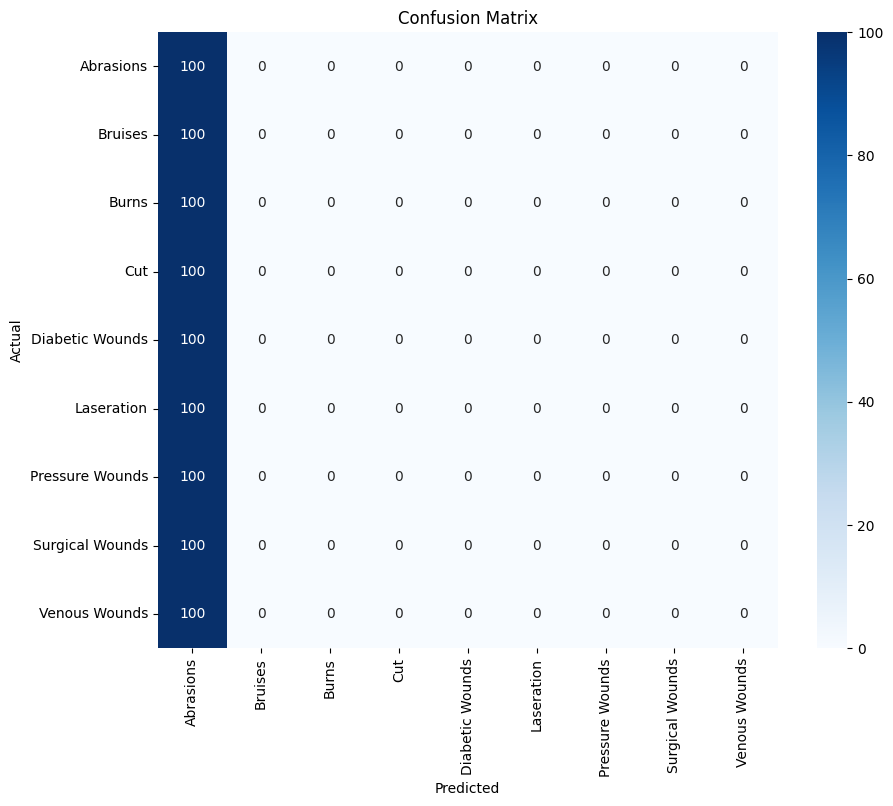

In [ ]:
# -------------- ใช้งานฟังก์ชัน ---------------- #
model_path = '/content/drive/MyDrive/RAC/truncated_model.pth'  # โมเดลที่ผ่านการทำ Layer Truncation
test_data_path = '/content/drive/MyDrive/RAC/Datat/test'  # path สำหรับข้อมูลทดสอบ

evaluate_truncated_model(model_path, test_data_path)

# Speed Check

In [ ]:
!pip install torchinfo

In [ ]:
import os
import time
import torch
import torch.nn as nn
from fastai.vision.all import *
import torch.nn.utils.prune as prune
from torchvision import models, transforms
from PIL import Image
from torchinfo import summary

# ตรวจสอบว่าใช้ GPU หรือไม่
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# **1. โหลดโมเดลที่ถูก Pruning**
model_path = '/content/drive/MyDrive/RAC/model93.pkl'  # Path ของโมเดลหลัง Pruning
learn = load_learner(model_path)  # โหลดโมเดล FastAI
model = learn.model.to(device)  # นำโมเดลไปยังอุปกรณ์ (CPU หรือ GPU)
model.eval()  # ตั้งค่าเป็นโหมด Evaluation

# **2. ตรวจสอบขนาดไฟล์โมเดล**
file_size = os.path.getsize(model_path) / (1024 * 1024)  # แปลงเป็น MB
print(f"📂 Model File Size: {file_size:.2f} MB")

# **3. ตรวจสอบจำนวนพารามิเตอร์ทั้งหมด**
total_params = sum(p.numel() for p in model.parameters())
print(f"🔢 Total Parameters: {total_params:,}")

# **4. ตรวจสอบจำนวนพารามิเตอร์ที่ยังใช้งานได้ (พารามิเตอร์ที่ไม่เป็น 0)**
active_params = sum(p.nonzero().size(0) for p in model.parameters() if p.requires_grad)
print(f"🟢 Active Parameters (Not Pruned): {active_params:,}")

# **5. คำนวณ FLOPs (Floating Point Operations)**
print("\n🧮 Model Computational Complexity (FLOPs):")
summary(model, input_size=(1, 3, 224, 224), col_names=["input_size", "output_size", "num_params", "mult_adds"])

# **6. โหลดและเตรียมภาพสำหรับ Inference**
def preprocess_image(image_path):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),  # ปรับขนาดให้ตรงกับที่ใช้ในการเทรน
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # ปรับ Normalize ตามโมเดลที่ฝึก
    ])

    image = Image.open(image_path).convert('RGB')  # โหลดรูปภาพ
    image = transform(image).unsqueeze(0)  # เพิ่ม batch dimension
    return image.to(device)

# ระบุ path ของภาพที่ต้องการทดสอบ
test_image_path = "/content/drive/MyDrive/RAC/Datat/test/Abrasions/aug_affine_shear_abrasions (65).jpg"  # เปลี่ยนเป็น path ของภาพที่ต้องการ

# **7. วัดเวลา Inference บนรูปเดียว**
def measure_single_inference_time(model, image_tensor):
    model.eval()
    start_time = time.time()

    with torch.no_grad():
        output = model(image_tensor)

    end_time = time.time()
    return end_time - start_time, output

# เตรียมภาพที่ต้องการทดสอบ
image_tensor = preprocess_image(test_image_path)

# วัดเวลา Inference และรับผลลัพธ์
inference_time, output = measure_single_inference_time(model, image_tensor)
print(f"\n⏳ Inference Time on Single Image: {inference_time:.4f} seconds")

# **8. แสดงผลการพยากรณ์**
predicted_class_idx = torch.argmax(output, dim=1).item()
predicted_class = learn.dls.vocab[predicted_class_idx]  # แปลงเป็นชื่อคลาส

print(f"🖼️ Predicted Class: {predicted_class} (Class Index: {predicted_class_idx})")


Using device: cuda
📂 Model File Size: 83.78 MB
🔢 Total Parameters: 21,816,640
🟢 Active Parameters (Not Pruned): 21,816,640

🧮 Model Computational Complexity (FLOPs):

⏳ Inference Time on Single Image: 0.0079 seconds
🖼️ Predicted Class: Abrasions (Class Index: 0)


In [ ]:
import os
import time
import torch
import torch.nn as nn
from fastai.vision.all import *
import torch.nn.utils.prune as prune
from torchvision import models, transforms
from PIL import Image
from torchinfo import summary

# ตรวจสอบว่าใช้ GPU หรือไม่
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# **1. โหลดโมเดลที่ถูก Pruning**
model_path = '/content/drive/MyDrive/RAC/pruned_model.pkl'  # Path ของโมเดลหลัง Pruning
learn = load_learner(model_path)  # โหลดโมเดล FastAI
model = learn.model.to(device)  # นำโมเดลไปยังอุปกรณ์ (CPU หรือ GPU)
model.eval()  # ตั้งค่าเป็นโหมด Evaluation

# **2. ตรวจสอบขนาดไฟล์โมเดล**
file_size = os.path.getsize(model_path) / (1024 * 1024)  # แปลงเป็น MB
print(f"📂 Model File Size: {file_size:.2f} MB")

# **3. ตรวจสอบจำนวนพารามิเตอร์ทั้งหมด**
total_params = sum(p.numel() for p in model.parameters())
print(f"🔢 Total Parameters: {total_params:,}")

# **4. ตรวจสอบจำนวนพารามิเตอร์ที่ยังใช้งานได้ (พารามิเตอร์ที่ไม่เป็น 0)**
active_params = sum(p.nonzero().size(0) for p in model.parameters() if p.requires_grad)
print(f"🟢 Active Parameters (Not Pruned): {active_params:,}")

# **5. คำนวณ FLOPs (Floating Point Operations)**
print("\n🧮 Model Computational Complexity (FLOPs):")
summary(model, input_size=(1, 3, 224, 224), col_names=["input_size", "output_size", "num_params", "mult_adds"])

# **6. โหลดและเตรียมภาพสำหรับ Inference**
def preprocess_image(image_path):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),  # ปรับขนาดให้ตรงกับที่ใช้ในการเทรน
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # ปรับ Normalize ตามโมเดลที่ฝึก
    ])

    image = Image.open(image_path).convert('RGB')  # โหลดรูปภาพ
    image = transform(image).unsqueeze(0)  # เพิ่ม batch dimension
    return image.to(device)

# ระบุ path ของภาพที่ต้องการทดสอบ
test_image_path = "/content/drive/MyDrive/RAC/Datat/test/Abrasions/aug_affine_shear_abrasions (65).jpg"  # เปลี่ยนเป็น path ของภาพที่ต้องการ

# **7. วัดเวลา Inference บนรูปเดียว**
def measure_single_inference_time(model, image_tensor):
    model.eval()
    start_time = time.time()

    with torch.no_grad():
        output = model(image_tensor)

    end_time = time.time()
    return end_time - start_time, output

# เตรียมภาพที่ต้องการทดสอบ
image_tensor = preprocess_image(test_image_path)

# วัดเวลา Inference และรับผลลัพธ์
inference_time, output = measure_single_inference_time(model, image_tensor)
print(f"\n⏳ Inference Time on Single Image: {inference_time:.4f} seconds")

# **8. แสดงผลการพยากรณ์**
predicted_class_idx = torch.argmax(output, dim=1).item()
predicted_class = learn.dls.vocab[predicted_class_idx]  # แปลงเป็นชื่อคลาส

print(f"🖼️ Predicted Class: {predicted_class} (Class Index: {predicted_class_idx})")


Using device: cuda
📂 Model File Size: 83.79 MB
🔢 Total Parameters: 21,816,640
🟢 Active Parameters (Not Pruned): 10,913,344

🧮 Model Computational Complexity (FLOPs):

⏳ Inference Time on Single Image: 0.0096 seconds
🖼️ Predicted Class: Abrasions (Class Index: 0)


In [ ]:
import os
import time
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
from torchinfo import summary

# ตรวจสอบว่าใช้ GPU หรือไม่
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# **1. กำหนดโครงสร้างของ Student Model (ResNet18)**
class StudentResNet(nn.Module):
    def __init__(self, num_classes=9):
        super(StudentResNet, self).__init__()
        self.student = models.resnet18(pretrained=False)  # ใช้ ResNet18 เป็น Student Model
        num_ftrs = self.student.fc.in_features
        self.student.fc = nn.Linear(num_ftrs, num_classes)  # Fully Connected Layer สำหรับ 9 คลาส

    def forward(self, x):
        return self.student(x)

# **2. โหลดโมเดล Student ที่ผ่านการทำ KD**
student_model_path = '/content/drive/MyDrive/RAC/student_model.pkl'  # Path ของโมเดล Student
model = StudentResNet().to(device)

# ✅ ใช้ map_location=device เพื่อป้องกันปัญหา CUDA ถ้าไม่มี GPU
model.load_state_dict(torch.load(student_model_path, map_location=device))
model.eval()  # ตั้งโมเดลเป็นโหมด Evaluation
print("✅ Student Model Loaded Successfully!")

# **3. ตรวจสอบขนาดไฟล์โมเดล**
file_size = os.path.getsize(student_model_path) / (1024 * 1024)  # แปลงเป็น MB
print(f"📂 Model File Size: {file_size:.2f} MB")

# **4. ตรวจสอบจำนวนพารามิเตอร์ทั้งหมด**
total_params = sum(p.numel() for p in model.parameters())
print(f"🔢 Total Parameters: {total_params:,}")

# **5. ตรวจสอบจำนวนพารามิเตอร์ที่ยังใช้งานได้ (ไม่ถูก Prune)**
active_params = sum(p.nonzero().size(0) for p in model.parameters() if p.requires_grad)
print(f"🟢 Active Parameters (Not Pruned): {active_params:,}")

# **6. คำนวณ FLOPs (Floating Point Operations)**
print("\n🧮 Model Computational Complexity (FLOPs):")
summary(model, input_size=(1, 3, 224, 224), col_names=["input_size", "output_size", "num_params", "mult_adds"])

# **7. โหลดและเตรียมภาพสำหรับ Inference**
def preprocess_image(image_path):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),  # ปรับขนาดให้ตรงกับที่ใช้ในการเทรน
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalize ตามที่ใช้ในการเทรน
    ])

    image = Image.open(image_path).convert('RGB')  # โหลดรูปภาพ
    image = transform(image).unsqueeze(0)  # เพิ่ม batch dimension
    return image.to(device)

# ระบุ path ของภาพที่ต้องการทดสอบ
test_image_path = "/content/drive/MyDrive/RAC/Datat/test/Abrasions/aug_affine_shear_abrasions (65).jpg"  # เปลี่ยนเป็น path ของภาพที่ต้องการ

# **8. วัดเวลา Inference บนรูปเดียว**
def measure_single_inference_time(model, image_tensor):
    model.eval()
    start_time = time.time()

    with torch.no_grad():
        output = model(image_tensor)

    end_time = time.time()
    return end_time - start_time, output

# เตรียมภาพที่ต้องการทดสอบ
image_tensor = preprocess_image(test_image_path)

# วัดเวลา Inference และรับผลลัพธ์
inference_time, output = measure_single_inference_time(model, image_tensor)
print(f"\n⏳ Inference Time on Single Image: {inference_time:.4f} seconds")

# **9. แสดงผลการพยากรณ์**
predicted_class_idx = torch.argmax(output, dim=1).item()
predicted_class = predicted_class_idx  # แสดงเป็นตัวเลข index ของคลาส

print(f"🖼️ Predicted Class: {predicted_class} (Class Index: {predicted_class_idx})")


Using device: cuda


<ipython-input-14-d96fcd3a59a7>:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(student_model_path, map_location=device))


✅ Student Model Loaded Successfully!
📂 Model File Size: 42.73 MB
🔢 Total Parameters: 11,181,129
🟢 Active Parameters (Not Pruned): 11,181,129

🧮 Model Computational Complexity (FLOPs):

⏳ Inference Time on Single Image: 0.0042 seconds
🖼️ Predicted Class: 7 (Class Index: 7)


In [ ]:
import os
import time
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
from torchinfo import summary

# ตรวจสอบว่าใช้ GPU หรือไม่
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# **1. กำหนดโครงสร้างของ Truncated Model**
class TruncatedResNet34(nn.Module):
    def __init__(self, num_classes=9):
        super(TruncatedResNet34, self).__init__()
        base_model = models.resnet34(pretrained=False)  # โหลดโครงสร้าง ResNet34
        self.features = nn.Sequential(*list(base_model.children())[:-1])  # ตัด Fully Connected Layer
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, num_classes)  # Fully Connected Layer ใหม่
        )

    def forward(self, x):
        x = self.features(x)
        x = self.fc(x)
        return x

# **2. โหลดโมเดลที่ผ่าน Layer Truncation**
truncated_model_path = '/content/drive/MyDrive/RAC/truncated_model.pth'  # Path ของโมเดล
model = TruncatedResNet34().to(device)

# ✅ ใช้ `strict=False` ถ้าพบปัญหา missing keys
model.load_state_dict(torch.load(truncated_model_path, map_location=device), strict=False)
model.eval()  # ตั้งโมเดลเป็นโหมด Evaluation
print("✅ Truncated Model Loaded Successfully!")

# **3. ตรวจสอบขนาดไฟล์โมเดล**
file_size = os.path.getsize(truncated_model_path) / (1024 * 1024)  # แปลงเป็น MB
print(f"📂 Model File Size: {file_size:.2f} MB")

# **4. ตรวจสอบจำนวนพารามิเตอร์ทั้งหมด**
total_params = sum(p.numel() for p in model.parameters())
print(f"🔢 Total Parameters: {total_params:,}")

# **5. ตรวจสอบจำนวนพารามิเตอร์ที่ยังใช้งานได้ (ไม่ถูก Prune)**
active_params = sum(p.nonzero().size(0) for p in model.parameters() if p.requires_grad)
print(f"🟢 Active Parameters (Not Pruned): {active_params:,}")

# **6. คำนวณ FLOPs (Floating Point Operations)**
print("\n🧮 Model Computational Complexity (FLOPs):")
summary(model, input_size=(1, 3, 224, 224), col_names=["input_size", "output_size", "num_params", "mult_adds"])

# **7. โหลดและเตรียมภาพสำหรับ Inference**
def preprocess_image(image_path):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),  # ปรับขนาดให้ตรงกับที่ใช้ในการเทรน
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalize ตามที่ใช้ในการเทรน
    ])

    image = Image.open(image_path).convert('RGB')  # โหลดรูปภาพ
    image = transform(image).unsqueeze(0)  # เพิ่ม batch dimension
    return image.to(device)

# ระบุ path ของภาพที่ต้องการทดสอบ
test_image_path = "/content/drive/MyDrive/RAC/Datat/test/Abrasions/aug_affine_shear_abrasions (65).jpg"  # เปลี่ยนเป็น path ของภาพที่ต้องการ

# **8. วัดเวลา Inference บนรูปเดียว**
def measure_single_inference_time(model, image_tensor):
    model.eval()
    start_time = time.time()

    with torch.no_grad():
        output = model(image_tensor)

    end_time = time.time()
    return end_time - start_time, output

# เตรียมภาพที่ต้องการทดสอบ
image_tensor = preprocess_image(test_image_path)

# วัดเวลา Inference และรับผลลัพธ์
inference_time, output = measure_single_inference_time(model, image_tensor)
print(f"\n⏳ Inference Time on Single Image: {inference_time:.4f} seconds")

# **9. แสดงผลการพยากรณ์**
predicted_class_idx = torch.argmax(output, dim=1).item()
predicted_class = predicted_class_idx  # แสดงเป็นตัวเลข index ของคลาส

print(f"🖼️ Predicted Class: {predicted_class} (Class Index: {predicted_class_idx})")


Using device: cuda


<ipython-input-16-8c9e67a75a95>:34: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(truncated_model_path, map_location=device), strict=False)


✅ Truncated Model Loaded Successfully!
📂 Model File Size: 81.35 MB
🔢 Total Parameters: 21,289,289
🟢 Active Parameters (Not Pruned): 21,280,773

🧮 Model Computational Complexity (FLOPs):

⏳ Inference Time on Single Image: 0.0160 seconds
🖼️ Predicted Class: 1 (Class Index: 1)


In [ ]:
import os
import time
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
from torchinfo import summary

# ตรวจสอบว่าใช้ GPU หรือไม่
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# **1. กำหนดโครงสร้างของ Student Model (ResNet18)**
class StudentResNet(nn.Module):
    def __init__(self, num_classes=9):
        super(StudentResNet, self).__init__()
        self.student = models.resnet18(pretrained=False)  # ใช้ ResNet18 เป็น Student Model
        num_ftrs = self.student.fc.in_features
        self.student.fc = nn.Linear(num_ftrs, num_classes)  # Fully Connected Layer สำหรับ 9 คลาส

    def forward(self, x):
        return self.student(x)

# **2. โหลดโมเดล Student ที่ผ่านการทำ KD**
student_model_path = '/content/drive/MyDrive/RAC/student_model_KD_E_DATA100.pkl'  # Path ของโมเดล Student
model = StudentResNet().to(device)

# ✅ ใช้ map_location=device เพื่อป้องกันปัญหา CUDA ถ้าไม่มี GPU
model.load_state_dict(torch.load(student_model_path, map_location=device))
model.eval()  # ตั้งโมเดลเป็นโหมด Evaluation
print("✅ Student Model Loaded Successfully!")

# **3. ตรวจสอบขนาดไฟล์โมเดล**
file_size = os.path.getsize(student_model_path) / (1024 * 1024)  # แปลงเป็น MB
print(f"📂 Model File Size: {file_size:.2f} MB")

# **4. ตรวจสอบจำนวนพารามิเตอร์ทั้งหมด**
total_params = sum(p.numel() for p in model.parameters())
print(f"🔢 Total Parameters: {total_params:,}")

# **5. ตรวจสอบจำนวนพารามิเตอร์ที่ยังใช้งานได้ (ไม่ถูก Prune)**
active_params = sum(p.nonzero().size(0) for p in model.parameters() if p.requires_grad)
print(f"🟢 Active Parameters (Not Pruned): {active_params:,}")

# **6. คำนวณ FLOPs (Floating Point Operations)**
print("\n🧮 Model Computational Complexity (FLOPs):")
summary(model, input_size=(1, 3, 224, 224), col_names=["input_size", "output_size", "num_params", "mult_adds"])

# **7. โหลดและเตรียมภาพสำหรับ Inference**
def preprocess_image(image_path):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),  # ปรับขนาดให้ตรงกับที่ใช้ในการเทรน
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalize ตามที่ใช้ในการเทรน
    ])

    image = Image.open(image_path).convert('RGB')  # โหลดรูปภาพ
    image = transform(image).unsqueeze(0)  # เพิ่ม batch dimension
    return image.to(device)

# ระบุ path ของภาพที่ต้องการทดสอบ
test_image_path = "/content/drive/MyDrive/RAC/Datat/test/Abrasions/aug_affine_shear_abrasions (65).jpg"  # เปลี่ยนเป็น path ของภาพที่ต้องการ

# **8. วัดเวลา Inference บนรูปเดียว**
def measure_single_inference_time(model, image_tensor):
    model.eval()
    start_time = time.time()

    with torch.no_grad():
        output = model(image_tensor)

    end_time = time.time()
    return end_time - start_time, output

# เตรียมภาพที่ต้องการทดสอบ
image_tensor = preprocess_image(test_image_path)

# วัดเวลา Inference และรับผลลัพธ์
inference_time, output = measure_single_inference_time(model, image_tensor)
print(f"\n⏳ Inference Time on Single Image: {inference_time:.4f} seconds")

# **9. แสดงผลการพยากรณ์**
predicted_class_idx = torch.argmax(output, dim=1).item()
predicted_class = predicted_class_idx  # แสดงเป็นตัวเลข index ของคลาส

print(f"🖼️ Predicted Class: {predicted_class} (Class Index: {predicted_class_idx})")


Using device: cuda


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
<ipython-input-4-6dd7ee9351b9>:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions

✅ Student Model Loaded Successfully!
📂 Model File Size: 42.73 MB
🔢 Total Parameters: 11,181,129
🟢 Active Parameters (Not Pruned): 11,181,129

🧮 Model Computational Complexity (FLOPs):

⏳ Inference Time on Single Image: 0.0027 seconds
🖼️ Predicted Class: 0 (Class Index: 0)


# Knowledge Distillation with Dynamic Temperature using Entropy Data


Using device: cuda


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Epoch [1/70], Loss: 2.1780
Epoch [2/70], Loss: 1.6780
Epoch [3/70], Loss: 1.3709
Epoch [4/70], Loss: 1.0348
Epoch [5/70], Loss: 0.7591
Epoch [6/70], Loss: 0.5660
Epoch [7/70], Loss: 0.3973
Epoch [8/70], Loss: 0.3366
Epoch [9/70], Loss: 0.2340
Epoch [10/70], Loss: 0.2025
Epoch [11/70], Loss: 0.1488
Epoch [12/70], Loss: 0.1162
Epoch [13/70], Loss: 0.0902
Epoch [14/70], Loss: 0.1006
Epoch [15/70], Loss: 0.1357
Epoch [16/70], Loss: 0.0308
Epoch [17/70], Loss: 0.1304
Epoch [18/70], Loss: 0.0356
Epoch [19/70], Loss: 0.0005
Epoch [20/70], Loss: 0.0583
Epoch [21/70], Loss: 0.0198
Epoch [22/70], Loss: 0.0086
Epoch [23/70], Loss: -0.0089
Epoch [24/70], Loss: 0.0169
Epoch [25/70], Loss: 0.1246
Epoch [26/70], Loss: -0.0061
Epoch [27/70], Loss: -0.0027
Epoch [28/70], Loss: 0.0324
Epoch [29/70], Loss: 0.0139
Epoch [30/70], Loss: 0.0254
Epoch [31/70], Loss: 0.0242
Epoch [32/70], Loss: 0.0043
Epoch [33/70], Loss: 0.0009
Epoch [34/70], Loss: -0.0206
Epoch [35/70], Loss: 0.0046
Epoch [36/70], Loss: 0.09

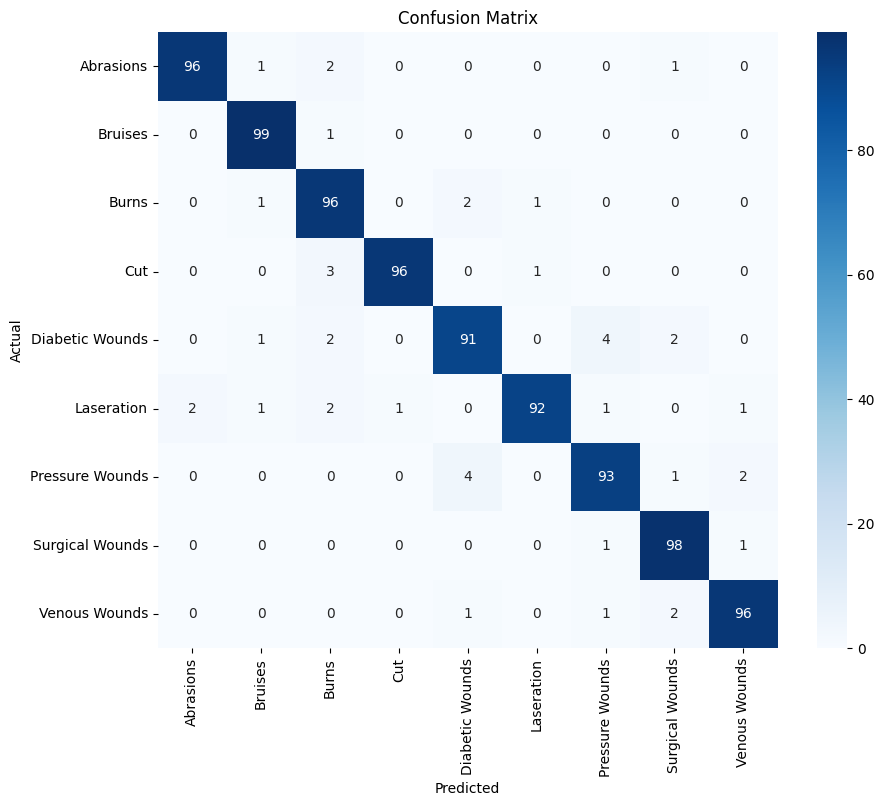

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from fastai.vision.all import *

# Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Load Teacher Model from a given .pkl file
teacher_model_path = '/content/drive/MyDrive/RAC/model93.pkl'  # Specify the path to the Teacher Model
teacher_learner = load_learner(teacher_model_path)
teacher_model = teacher_learner.model.to(device)
teacher_model.eval()  # Set model to evaluation mode

# Define Student Model (Reduced ResNet18)
class StudentResNet(nn.Module):
    def __init__(self):
        super(StudentResNet, self).__init__()
        self.student = models.resnet18(pretrained=False)  # Smaller model
        num_ftrs = self.student.fc.in_features
        self.student.fc = nn.Linear(num_ftrs, 9)  # Output for 9 classes

    def forward(self, x):
        return self.student(x)

student_model = StudentResNet().to(device)

class EntropyWeightedKDLoss(nn.Module):
    def __init__(self, alpha=0.5, beta=2.0):
        super(EntropyWeightedKDLoss, self).__init__()
        self.alpha = alpha
        self.beta = beta
        self.criterion_ce = nn.CrossEntropyLoss()
        self.criterion_kl = nn.KLDivLoss(reduction='batchmean')

    def forward(self, student_logits, teacher_logits, labels):
        # Compute probabilities from logits
        teacher_probs = torch.softmax(teacher_logits, dim=1)

        # Compute entropy for each sample
        entropy = -torch.sum(teacher_probs * torch.log(teacher_probs + 1e-9), dim=1)

        # Normalize entropy
        entropy_min = entropy.min()
        entropy_max = entropy.max()
        entropy_scaled = (entropy - entropy_min) / (entropy_max - entropy_min)

        # Dynamic Temperature
        T = torch.clamp(1.0 + self.beta * entropy_scaled, min=1.0, max=5.0)

        # Adaptive Alpha (ให้ KL สำคัญเมื่อ entropy ต่ำ และ CE สำคัญเมื่อ entropy สูง)
        adaptive_alpha = torch.sigmoid(2 - entropy)

        # Compute KL Loss with dynamic T
        kl_loss = self.criterion_kl(
            torch.log_softmax(student_logits / T.unsqueeze(1), dim=1),
            teacher_probs / T.unsqueeze(1)
        )

        # Compute Cross-Entropy Loss
        ce_loss = self.criterion_ce(student_logits, labels)

        # Compute Contrastive Loss (Fix)
        contrastive_loss = F.cosine_embedding_loss(
            student_logits, teacher_logits, torch.ones_like(labels, dtype=torch.float).to(device)
        )

        # Combine losses (Fix: Reduce to scalar)
        total_loss = (adaptive_alpha * kl_loss * T.mean().item() ** 2) + ((1 - adaptive_alpha) * ce_loss) + (0.1 * contrastive_loss)

        return total_loss.mean()  # Ensure scalar output

# Dataset and DataLoader
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder('/content/drive/MyDrive/RAC/Datat/train', transform=data_transforms)
val_dataset = datasets.ImageFolder('/content/drive/MyDrive/RAC/Datat/val', transform=data_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

# Training Configuration
epochs = 70
lr = 1e-3
optimizer = optim.Adam(student_model.parameters(), lr=lr)
kd_loss_fn = EntropyWeightedKDLoss(alpha=0.5, beta=2.0)

# Training Loop
def train_kd(teacher_model, student_model, train_loader, kd_loss_fn, optimizer, epochs):
    teacher_model.eval()
    student_model.train()

    for epoch in range(epochs):
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            with torch.no_grad():
                teacher_logits = teacher_model(inputs)

            student_logits = student_model(inputs)
            loss = kd_loss_fn(student_logits, teacher_logits, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss/len(train_loader):.4f}")

    print("Training Complete")
    return student_model

# Train the Student Model
trained_student_model = train_kd(teacher_model, student_model, train_loader, kd_loss_fn, optimizer, epochs)

# Save the Model in .pkl format
student_model_path = '/content/drive/MyDrive/RAC/student_model_KD_E_DATA100.pkl'
torch.save(trained_student_model.state_dict(), student_model_path)
print(f"Student Model Saved at {student_model_path}")

# Evaluate Model and Show Metrics
def evaluate_and_show_metrics(model, dataloader, classes):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    conf_matrix = confusion_matrix(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted')
    recall = recall_score(all_labels, all_preds, average='weighted')
    acc = accuracy_score(all_labels, all_preds)

    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Accuracy: {acc:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"Recall: {recall:.4f}")

    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()

# Class names from the dataset
test_dataset = datasets.ImageFolder('/content/drive/MyDrive/RAC/Datat/test', transform=data_transforms)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)
class_names = test_dataset.classes

# Evaluate the model
evaluate_and_show_metrics(student_model, test_loader, class_names)

Using device: cuda


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
<ipython-input-4-aaf6142ef83c>:43: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions

Accuracy: 0.9522
F1 Score: 0.9522
Recall: 0.9522
Classes from trained model: ['Abrasions', 'Bruises', 'Burns', 'Cut', 'Diabetic Wounds', 'Laseration', 'Pressure Wounds', 'Surgical Wounds', 'Venous Wounds']
Number of test images: 900
Confusion Matrix:
[[96  1  2  0  0  0  0  1  0]
 [ 0 99  1  0  0  0  0  0  0]
 [ 0  1 96  0  2  1  0  0  0]
 [ 0  0  3 96  0  1  0  0  0]
 [ 0  1  2  0 91  0  4  2  0]
 [ 2  1  2  1  0 92  1  0  1]
 [ 0  0  0  0  4  0 93  1  2]
 [ 0  0  0  0  0  0  1 98  1]
 [ 0  0  0  0  1  0  1  2 96]]


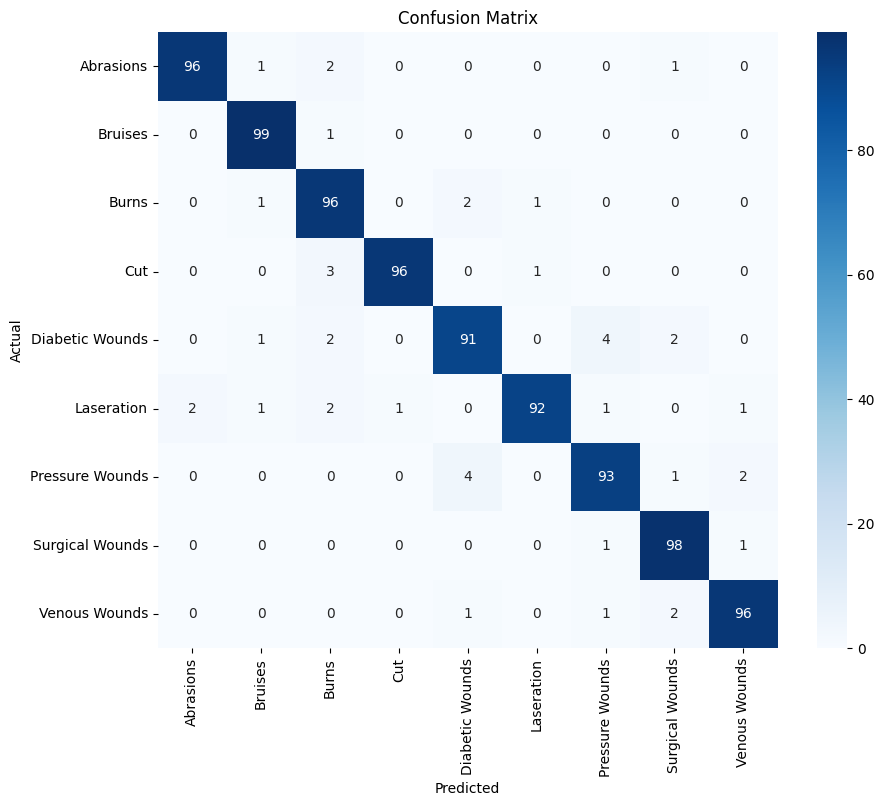

In [ ]:
# -------------- ใช้งานฟังก์ชัน ---------------- #
model_path = '/content/drive/MyDrive/RAC/student_model_KD_E_DATA100.pkl'  # โมเดลที่ผ่านการทำ KD
test_data_path = '/content/drive/MyDrive/RAC/Datat/test'  # path สำหรับข้อมูลทดสอบ

evaluate_kd_model(model_path, test_data_path)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from fastai.vision.all import *

# Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Load Teacher Model from a given .pkl file
teacher_model_path = '/content/drive/MyDrive/RAC/model93.pkl'  # Specify the path to the Teacher Model
teacher_learner = load_learner(teacher_model_path)
teacher_model = teacher_learner.model.to(device)
teacher_model.eval()  # Set model to evaluation mode

# Define Student Model (Reduced ResNet18)
class StudentResNet(nn.Module):
    def __init__(self):
        super(StudentResNet, self).__init__()
        self.student = models.resnet18(pretrained=False)  # Smaller model
        num_ftrs = self.student.fc.in_features
        self.student.fc = nn.Linear(num_ftrs, 9)  # Output for 9 classes

    def forward(self, x):
        return self.student(x)

student_model = StudentResNet().to(device)

class EntropyWeightedKDLoss(nn.Module):
    def __init__(self, alpha=0.5, beta=2.0):
        super(EntropyWeightedKDLoss, self).__init__()
        self.alpha = alpha
        self.beta = beta
        self.criterion_ce = nn.CrossEntropyLoss()
        self.criterion_kl = nn.KLDivLoss(reduction='batchmean')

    def forward(self, student_logits, teacher_logits, labels):
        # Compute probabilities from logits
        teacher_probs = torch.softmax(teacher_logits, dim=1)

        # Compute entropy for each sample
        entropy = -torch.sum(teacher_probs * torch.log(teacher_probs + 1e-9), dim=1)

        # Normalize entropy
        entropy_min = entropy.min()
        entropy_max = entropy.max()
        entropy_scaled = (entropy - entropy_min) / (entropy_max - entropy_min)

        # Dynamic Temperature
        T = torch.clamp(1.0 + self.beta * entropy_scaled, min=1.0, max=5.0)

        # Adaptive Alpha (ให้ KL สำคัญเมื่อ entropy ต่ำ และ CE สำคัญเมื่อ entropy สูง)
        adaptive_alpha = torch.sigmoid(2 - entropy)

        # Compute KL Loss with dynamic T
        kl_loss = self.criterion_kl(
            torch.log_softmax(student_logits / T.unsqueeze(1), dim=1),
            teacher_probs / T.unsqueeze(1)
        )

        # Compute Cross-Entropy Loss
        ce_loss = self.criterion_ce(student_logits, labels)

        # Compute Contrastive Loss (Fix)
        contrastive_loss = F.cosine_embedding_loss(
            student_logits, teacher_logits, torch.ones_like(labels, dtype=torch.float).to(device)
        )

        # Combine losses (Fix: Reduce to scalar)
        total_loss = (adaptive_alpha * kl_loss * T.mean().item() ** 2) + ((1 - adaptive_alpha) * ce_loss) + (0.1 * contrastive_loss)

        return total_loss.mean()  # Ensure scalar output

# Dataset and DataLoader
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder('/content/drive/MyDrive/RAC/Datat/train', transform=data_transforms)
val_dataset = datasets.ImageFolder('/content/drive/MyDrive/RAC/Datat/val', transform=data_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

# Training Configuration
epochs = 70
lr = 1e-3
optimizer = optim.Adam(student_model.parameters(), lr=lr)
kd_loss_fn = EntropyWeightedKDLoss(alpha=0.5, beta=2.0)

# Training Loop
def train_kd(teacher_model, student_model, train_loader, kd_loss_fn, optimizer, epochs):
    teacher_model.eval()
    student_model.train()

    for epoch in range(epochs):
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            with torch.no_grad():
                teacher_logits = teacher_model(inputs)

            student_logits = student_model(inputs)
            loss = kd_loss_fn(student_logits, teacher_logits, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss/len(train_loader):.4f}")

    print("Training Complete")
    return student_model

# Train the Student Model
trained_student_model = train_kd(teacher_model, student_model, train_loader, kd_loss_fn, optimizer, epochs)

# Save the Model in .pkl format
student_model_path = '/content/drive/MyDrive/RAC/student_model_KD_E_DATA100.pkl'
torch.save(trained_student_model.state_dict(), student_model_path)
print(f"Student Model Saved at {student_model_path}")

# Evaluate Model and Show Metrics
def evaluate_and_show_metrics(model, dataloader, classes):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    conf_matrix = confusion_matrix(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted')
    recall = recall_score(all_labels, all_preds, average='weighted')
    acc = accuracy_score(all_labels, all_preds)

    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Accuracy: {acc:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"Recall: {recall:.4f}")

    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()

# Class names from the dataset
test_dataset = datasets.ImageFolder('/content/drive/MyDrive/RAC/Datat/test', transform=data_transforms)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)
class_names = test_dataset.classes

# Evaluate the model
evaluate_and_show_metrics(student_model, test_loader, class_names)


# Not use
# Knowledge Distillation with Dynamic Temperature using Entropy


ไม่เกิดการลบกันเกิดขึ้น ฝั่งนักเรียนใช้ T = 1

Using device: cuda
Epoch [1/10], Loss: 2.0572
Epoch [2/10], Loss: 1.4961
Epoch [3/10], Loss: 1.2858
Epoch [4/10], Loss: 1.0889
Epoch [5/10], Loss: 1.0361
Epoch [6/10], Loss: 1.2060
Epoch [7/10], Loss: 0.8114
Epoch [8/10], Loss: 0.8331
Epoch [9/10], Loss: 0.6836
Epoch [10/10], Loss: 0.9436
Training Complete
Student Model Saved at /content/drive/MyDrive/RAC/student_model_ECLASS2.pkl
Confusion Matrix:
[[86  0  1  2  1  8  1  0  1]
 [30 56  2  0  1  6  4  0  1]
 [ 2  1 77  0  3  8  7  0  2]
 [35  0  0 21  0 43  0  0  1]
 [ 8  1 13  1 27 11 24  3 12]
 [ 2  0  1  2  0 92  2  1  0]
 [ 0  0  2  0  5 11 67  1 14]
 [ 9  4  8  2  2 13 22 28 12]
 [ 1  2  1  0  1  2  1  0 92]]
Accuracy: 0.6067
F1 Score: 0.5773
Recall: 0.6067


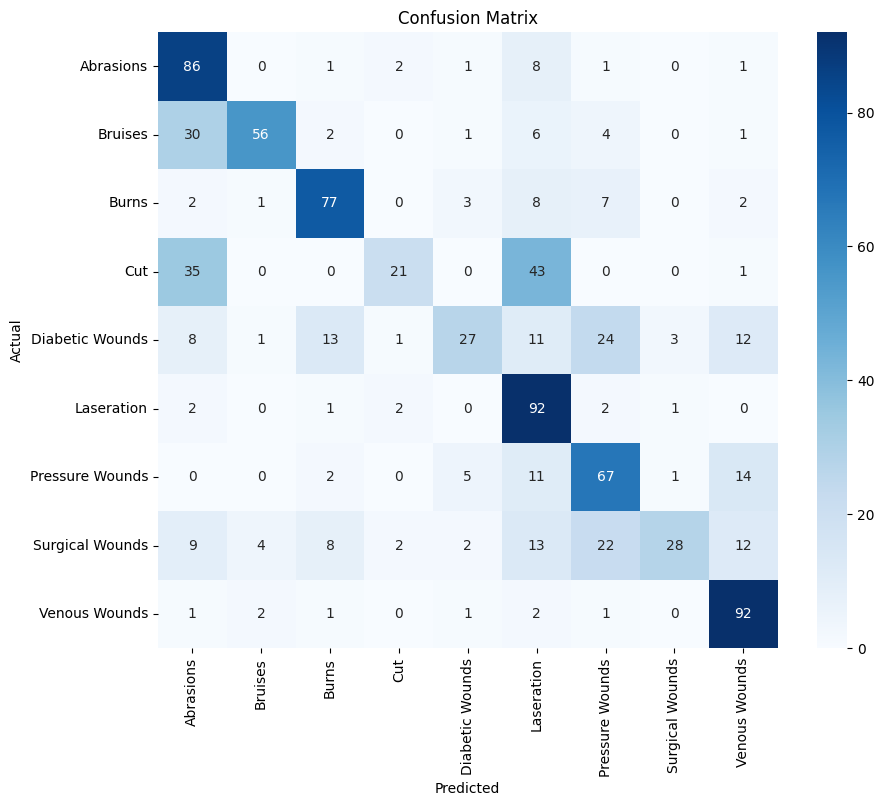

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from fastai.vision.all import *

# Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Load Teacher Model from a given .pkl file
teacher_model_path = '/content/drive/MyDrive/RAC/model93.pkl'  # Specify the path to the Teacher Model
teacher_learner = load_learner(teacher_model_path)
teacher_model = teacher_learner.model.to(device)
teacher_model.eval()  # Set model to evaluation mode

# Define Student Model (Reduced ResNet18)
class StudentResNet(nn.Module):
    def __init__(self):
        super(StudentResNet, self).__init__()
        self.student = models.resnet18(pretrained=False)  # Smaller model
        num_ftrs = self.student.fc.in_features
        self.student.fc = nn.Linear(num_ftrs, 9)  # Output for 9 classes

    def forward(self, x):
        return self.student(x)

student_model = StudentResNet().to(device)

class KDLoss(nn.Module):
    def __init__(self, alpha=0.5):
        super(KDLoss, self).__init__()
        self.alpha = alpha
        self.criterion_ce = nn.CrossEntropyLoss()
        self.criterion_kl = nn.KLDivLoss(reduction='batchmean')

    def forward(self, student_logits, teacher_logits, labels, hard_label_entropies, teacher_entropies, student_entropies):
        student_T = torch.ones_like(student_logits[:, 0], device=student_logits.device)
        teacher_T = teacher_entropies
        distillation_T = torch.abs(teacher_entropies - student_entropies)

        # Ensure distillation_T is broadcastable to the same shape as the logits
        distillation_T = distillation_T.unsqueeze(1).expand_as(student_logits)  # Add singleton dimension for broadcasting

        kl_loss = self.criterion_kl(
            F.log_softmax(student_logits / distillation_T, dim=1),
            F.softmax(teacher_logits / teacher_T.unsqueeze(1).expand_as(teacher_logits), dim=1)  # Broadcast teacher_T as well
        )
        ce_loss = self.criterion_ce(student_logits / student_T.unsqueeze(1).expand_as(student_logits), labels)  # Ensure student_T is broadcastable

        return (self.alpha * kl_loss) + ((1 - self.alpha) * ce_loss)


# Dataset and DataLoader
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder('/content/drive/MyDrive/RAC/Datat/train', transform=data_transforms)
val_dataset = datasets.ImageFolder('/content/drive/MyDrive/RAC/Datat/val', transform=data_transforms)
test_dataset = datasets.ImageFolder('/content/drive/MyDrive/RAC/Datat/test', transform=data_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

# Training Configuration
epochs = 10
lr = 1e-3
optimizer = optim.Adam(student_model.parameters(), lr=lr)
kd_loss_fn = KDLoss(alpha=0.5)

# Training Loop
def train_kd(teacher_model, student_model, train_loader, val_loader, kd_loss_fn, optimizer, epochs):
    teacher_model.eval()
    student_model.train()

    for epoch in range(epochs):
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            with torch.no_grad():
                teacher_logits = teacher_model(inputs)
                hard_label_entropies = -torch.sum(F.softmax(teacher_logits, dim=1) * F.log_softmax(teacher_logits, dim=1), dim=1)
                teacher_entropies = -torch.sum(F.softmax(teacher_logits, dim=1) * F.log_softmax(teacher_logits, dim=1), dim=1)

            student_logits = student_model(inputs)
            student_entropies = -torch.sum(F.softmax(student_logits, dim=1) * F.log_softmax(student_logits, dim=1), dim=1)

            loss = kd_loss_fn(student_logits, teacher_logits, labels, hard_label_entropies, teacher_entropies, student_entropies)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss/len(train_loader):.4f}")

    print("Training Complete")
    return student_model

# Train the Student Model
trained_student_model = train_kd(teacher_model, student_model, train_loader, val_loader, kd_loss_fn, optimizer, epochs)

# Save the Model in .pkl format
student_model_path = '/content/drive/MyDrive/RAC/student_model_ECLASS1.pkl'
torch.save(trained_student_model.state_dict(), student_model_path)
print(f"Student Model Saved at {student_model_path}")

# Evaluate Model and Show Metrics
def evaluate_and_show_metrics(model, dataloader, classes):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    conf_matrix = confusion_matrix(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted')
    recall = recall_score(all_labels, all_preds, average='weighted')
    acc = accuracy_score(all_labels, all_preds)

    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Accuracy: {acc:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"Recall: {recall:.4f}")

    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()

# Evaluate the model
evaluate_and_show_metrics(student_model, test_loader, test_dataset.classes)


ใช้ ACC หารตัด Tยกกำลัง2

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from fastai.vision.all import *

# Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Load Teacher Model from a given .pkl file
teacher_model_path = '/content/drive/MyDrive/RAC/model93.pkl'  # Specify the path to the Teacher Model
teacher_learner = load_learner(teacher_model_path)
teacher_model = teacher_learner.model.to(device)
teacher_model.eval()  # Set model to evaluation mode

data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder('/content/drive/MyDrive/RAC/Datat/train', transform=data_transforms)
val_dataset = datasets.ImageFolder('/content/drive/MyDrive/RAC/Datat/val', transform=data_transforms)
test_dataset = datasets.ImageFolder('/content/drive/MyDrive/RAC/Datat/test', transform=data_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

class KDLoss(nn.Module):
    def __init__(self, alpha=0.5, temperature=4):
        super(KDLoss, self).__init__()
        self.alpha = alpha
        self.temperature = temperature
        self.criterion_ce = nn.CrossEntropyLoss()
        self.criterion_kl = nn.KLDivLoss(reduction='batchmean')

    def forward(self, student_logits, teacher_logits, labels, ACC): #hard_label_entropies, teacher_entropies, student_entropies
        # student_T = (hard_label_entropies - student_entropies).abs()  #กลับไปใช้แบบเดิม
        # teacher_T = teacher_entropies
        # distillation_T = (teacher_entropies - student_entropies).abs()
        # print(hard_label_entropies)
        # print(student_entropies)
        # print(teacher_entropies)
        # print(student_entropies)
        # print(student_T)
        # print(teacher_T)
        # print(distillation_T)
        # print(type(student_T))
        # print(type(teacher_T))

        # distillation_T = distillation_T.unsqueeze(1).expand_as(student_logits)

        #kl_loss = self.criterion_kl(
            #F.log_softmax(student_logits / distillation_T, dim=1), #เช็คให้ใช้เป็นผลรวม
            #F.softmax(teacher_logits / distillation_T, dim=1) #เช็คให้ใช้เป็นผลรวม
        #)

        kl_loss = self.criterion_kl(
            F.log_softmax(student_logits / self.temperature, dim=1),
            F.softmax(teacher_logits / self.temperature, dim=1)
        )
        ce_loss = self.criterion_ce(student_logits, labels)

        return ((self.alpha * kl_loss) + ((1 - self.alpha) * (ce_loss / ACC)))

# Define Student Model (Reduced ResNet18)
class StudentResNet(nn.Module):
    def __init__(self):
        super(StudentResNet, self).__init__()
        self.student = models.resnet18(pretrained=False)  # Smaller model
        num_ftrs = self.student.fc.in_features
        self.student.fc = nn.Linear(num_ftrs, 9)  # Output for 9 classes

    def forward(self, x):
        return self.student(x)

student_model = StudentResNet().to(device)

# Training Configuration
epochs = 20
lr = 1e-3
optimizer = optim.Adam(student_model.parameters(), lr=lr)
kd_loss_fn = KDLoss(alpha=0.5)

# Evaluate Model and Show Metrics
def evaluate_and_show_metrics(model, dataloader, classes):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    conf_matrix = confusion_matrix(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted')
    recall = recall_score(all_labels, all_preds, average='weighted')
    acc = accuracy_score(all_labels, all_preds)

    return acc

# Training Loop
def train_kd(teacher_model, student_model, train_loader, val_loader, kd_loss_fn, optimizer, epochs):
    teacher_model.eval()
    student_model.train()

    for epoch in range(epochs):
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            with torch.no_grad():
                teacher_logits = teacher_model(inputs)
                # one_hot_labels = F.one_hot(labels, num_classes=teacher_logits.shape[1]).float()
                # hard_label_entropies = -torch.sum(one_hot_labels * torch.log(one_hot_labels + 1e-9), dim=1)  # แก้ให้ใช้ One-hot Labels
                # teacher_probs = F.softmax(teacher_logits, dim=1)
                # teacher_entropies = -torch.sum(teacher_probs * torch.log(teacher_probs + 1e-9), dim=1)  # แก้ให้ใช้ค่าจริงของ Probability

            student_logits = student_model(inputs)
            # student_probs = F.softmax(student_logits, dim=1)
            # student_entropies = -torch.sum(student_probs * torch.log(student_probs + 1e-9), dim=1)  # แก้ให้ใช้ค่าจริงของ Probability
            ACC = evaluate_and_show_metrics(student_model, test_loader, test_dataset.classes)
            loss = kd_loss_fn(student_logits, teacher_logits, labels, ACC) #hard_label_entropies, teacher_entropies, student_entropies

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(ACC)
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss/len(train_loader):.4f}")

    print("Training Complete")
    return student_model

# Train the Student Model
trained_student_model = train_kd(teacher_model, student_model, train_loader, val_loader, kd_loss_fn, optimizer, epochs)

# Save the Model in .pkl format
student_model_path = '/content/drive/MyDrive/RAC/student_model_ECLASS2.pkl'
torch.save(trained_student_model.state_dict(), student_model_path)
print(f"Student Model Saved at {student_model_path}")

# Evaluate Model and Show Metrics
def evaluate_and_show_metrics(model, dataloader, classes):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    conf_matrix = confusion_matrix(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted')
    recall = recall_score(all_labels, all_preds, average='weighted')
    acc = accuracy_score(all_labels, all_preds)

    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Accuracy: {acc:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"Recall: {recall:.4f}")

    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()

# Evaluate the model
evaluate_and_show_metrics(student_model, test_loader, test_dataset.classes)


Using device: cuda


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


0.18
Epoch [1/20], Loss: 8.8699
0.2877777777777778
Epoch [2/20], Loss: 4.9884
0.36666666666666664
Epoch [3/20], Loss: 3.6864
0.4166666666666667
Epoch [4/20], Loss: 2.7511
0.5233333333333333
Epoch [5/20], Loss: 1.9138
0.6711111111111111
Epoch [6/20], Loss: 1.3683


Kfold

In [ ]:
# import os
# import shutil
# from sklearn.model_selection import StratifiedKFold
# import numpy as np

# # กำหนดพาธ
# input_dir = "/content/drive/MyDrive/RAC/Data224"
# output_dir = "/content/drive/MyDrive/RAC/Kfold"
# classes = ['Normal', 'Laseration', 'Surgical Wounds', 'Burns', 'Abrasions',
#            'Bruises', 'Cut', 'Venous Wounds', 'Diabetic Wounds', 'Pressure Wounds']
# k_folds = 5  # จำนวน fold สำหรับ cross-validation

# # สร้าง output directory หากยังไม่มี
# os.makedirs(output_dir, exist_ok=True)

# # อ่านข้อมูลทั้งหมด
# data = []  # เก็บข้อมูลทั้งหมดในรูป (ไฟล์, คลาส)
# labels = []  # เก็บคลาสของไฟล์
# for class_name in classes:
#     class_dir = os.path.join(input_dir, class_name)
#     if os.path.exists(class_dir):
#         for file_name in os.listdir(class_dir):
#             data.append(os.path.join(class_dir, file_name))
#             labels.append(class_name)

# # เปลี่ยน labels เป็นเลขสำหรับ StratifiedKFold
# class_to_index = {class_name: idx for idx, class_name in enumerate(classes)}
# labels_numeric = [class_to_index[label] for label in labels]

# # สร้าง StratifiedKFold
# skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)

# for fold, (train_idx, val_idx) in enumerate(skf.split(data, labels_numeric)):
#     fold_dir = os.path.join(output_dir, f"fold_{fold + 1}")
#     train_dir = os.path.join(fold_dir, "train")
#     val_dir = os.path.join(fold_dir, "val")

#     # สร้าง train/val directories
#     for directory in [train_dir, val_dir]:
#         for class_name in classes:
#             os.makedirs(os.path.join(directory, class_name), exist_ok=True)

#     # ย้ายไฟล์ไปยัง train และ val
#     for idx in train_idx:
#         src = data[idx]
#         dst = os.path.join(train_dir, labels[idx], os.path.basename(src))
#         shutil.copy(src, dst)

#     for idx in val_idx:
#         src = data[idx]
#         dst = os.path.join(val_dir, labels[idx], os.path.basename(src))
#         shutil.copy(src, dst)

#     print(f"Fold {fold + 1} created: Train={len(train_idx)} Val={len(val_idx)}")

Fold 1 created: Train=8000 Val=2000
Fold 2 created: Train=8000 Val=2000
Fold 3 created: Train=8000 Val=2000
Fold 4 created: Train=8000 Val=2000
Fold 5 created: Train=8000 Val=2000


         Subfolder  FileCount
0           Normal        800
1       Laseration        800
2  Surgical Wounds        800
3            Burns        800
4        Abrasions        800
5          Bruises        800
6              Cut        800
7    Venous Wounds        800
8  Diabetic Wounds        800
9  Pressure Wounds        800


<ipython-input-14-24e8cfa4c09d>:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Subfolder', y='FileCount', data=df, palette='Blues_d')


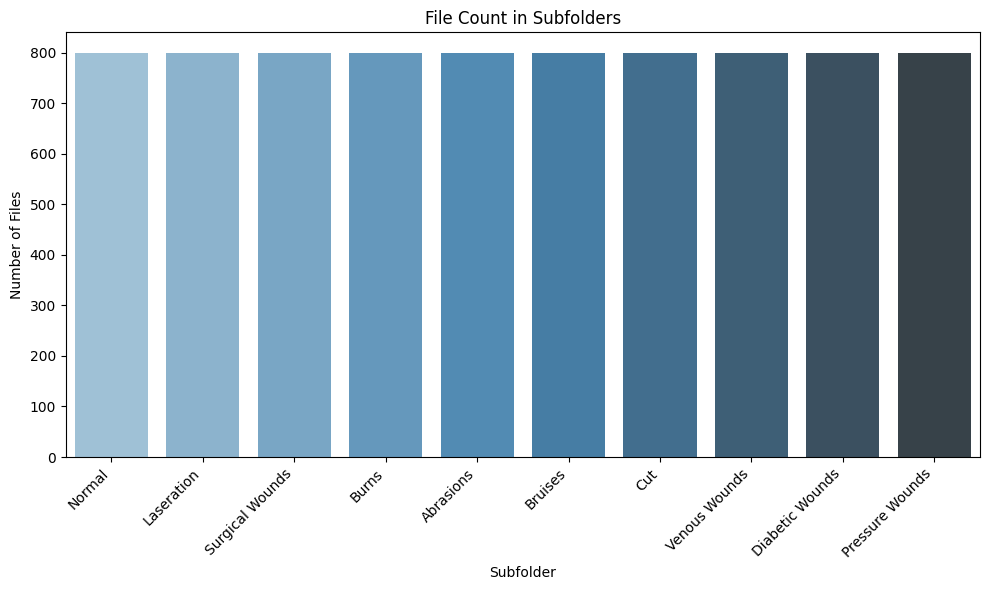

In [ ]:
# plot_file_count_in_subfolders('/content/drive/MyDrive/RAC/Kfold/fold_1/train')

         Subfolder  FileCount
0           Normal        200
1       Laseration        200
2  Surgical Wounds        200
3            Burns        200
4        Abrasions        200
5          Bruises        200
6              Cut        200
7    Venous Wounds        200
8  Diabetic Wounds        200
9  Pressure Wounds        200


<ipython-input-14-24e8cfa4c09d>:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Subfolder', y='FileCount', data=df, palette='Blues_d')


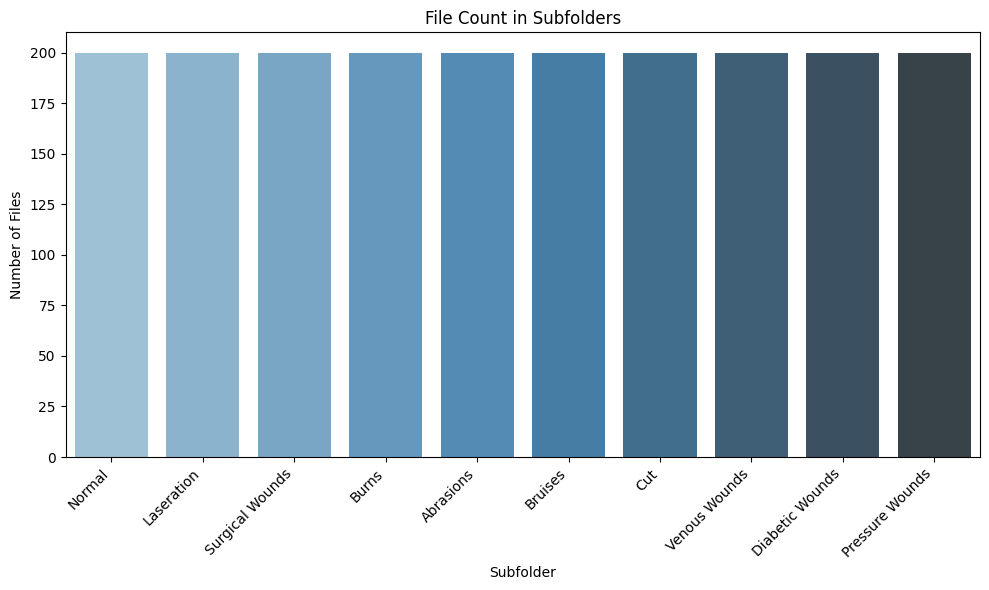

In [ ]:
# plot_file_count_in_subfolders('/content/drive/MyDrive/RAC/Kfold/fold_1/val')